# M6 EnComs Metagenomics - Metabolism analysis

In [1]:
#import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
import scipy
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('white')
sns.set_context('paper')
mpl.rcParams['font.family'] = 'Helvetica'
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42


In [2]:
#Print package versions
print('\n'.join(f'{m.__name__}=={m.__version__}' for m in globals().values() if getattr(m, '__version__', None)))

pandas==3.0.1
numpy==2.4.2
matplotlib==3.10.8
scipy==1.17.1
seaborn==0.13.2


In [3]:
#Load gene calls and coverage for each MAG

bin_order = ['Bin_1','Bin_2','Bin_3','Bin_4','Bin_5','Bin_6','Bin_7','Bin_8','Bin_9','Bin_10','Bin_11','Bin_12','Bin_13',
             'Bin_14','Bin_15','Bin_16','Bin_17','Bin_18','Bin_19','Bin_20','Bin_21','Bin_22','Bin_23','Bin_24','Bin_25',
             'Bin_26','Bin_27','Bin_28','Bin_29','Bin_30','Bin_31','Bin_32','Bin_33','Bin_34','Bin_35','Bin_36','Bin_37',
             'Bin_38','Bin_39','Bin_40','Bin_41'] #these get out of order b/c numbers and strings so use this list to put them in order manually

#Use CheckM data to get list of bins above completeness threshold
checkM_df = pd.read_csv('./data/CheckM_summary_table.tsv',sep='\t')
checkM_df['bin_id'] = checkM_df['Bin Name'].str.split('-',expand=True)[0]

#The completeness threshold is more strict here because we want to trust the completeness of a metabolic pathway in the MAGs with some confidence
#But, 90% is still far from perfect. We can probably trust that a pathway is complete in a MAG, but we can't be sure that incompleteness isn't simply due to missing coverage
percent_completion_threshold = 90

good_bin_list = checkM_df[checkM_df['Completeness']>=percent_completion_threshold]['bin_id'].to_list() #Only keep MAGs that are at least 90% complete

good_bin_list = [i for i in bin_order if i in good_bin_list and i not in ['Bin_41']] #Bin_41 presents duplication issues with pathways downstream, so we're going to exclude it manually

#Use this dictionary to assign better labels in place of the bin ids
bin_label_rename_dict = {
 'Bin_1':'Neor 1',
 'Bin_2':'Allo 2',
 'Bin_3':'Lysi 3',
 'Bin_4':'Neor 4',
 'Bin_5':'Robe 5',
 'Bin_6':'Arth 6',
 'Bin_7':'Paen 7',
 'Bin_8':'Meso 8',
 'Bin_9':'Noca 9',
 'Bin_10':'Lacu 10',
 'Bin_11':'Arth 11',
 'Bin_12':'Arth 12',
 'Bin_13':'Para 13',
 'Bin_14':'Baci 14',
 'Bin_15':'Arth 15',
 'Bin_16':'Jani 16',
 'Bin_17':'17',
 'Bin_18':'Arth 18',
 'Bin_19':'Arth 19',
 'Bin_20':'Flav 20',
 'Bin_21':'Fict 21',
 'Bin_22':'Cell 22',
 'Bin_23':'23',
 'Bin_24':'24',
 'Bin_25':'Arth 25',
 'Bin_26':'Aero 26',
 'Bin_27':'Baci 27',
 'Bin_28':'Arth 28',
 'Bin_29':'Noca 29',
 'Bin_30':'Noca 30',
 'Bin_31':'Stre 31',
 'Bin_32':'Stre 32',
 'Bin_33':'33',
 'Bin_34':'Neob 34',
 'Bin_35':'Paen 35',
 'Bin_36':'Robe 36',
 'Bin_37':'Micr 37',
 'Bin_38':'38',
 'Bin_39':'Noca 39',
 'Bin_40':'Noca 40',
 'Bin_41':'Arth 41'
}

#Read in the basic information (taxonomy,etc.) about each bin
bin_info_df = pd.read_csv('./data/bins_summary.txt',sep='\t',index_col='bins')
bin_info_df = bin_info_df.reindex(bin_order) #make sure this is in the same order as the bin_abund_df

#store the gene call dfs for each MAG in this dictionary
bin_gene_calls_dict = {}

for b in good_bin_list:
    gene_calls = pd.read_csv(f'./data/SUMMARY_manual_bins/bin_by_bin/{b}/{b}-gene_calls.txt',sep='\t').fillna('none')
    bin_gene_calls_dict[bin_label_rename_dict[b]] = gene_calls

bin_gene_calls_dict['Neor 1']

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
0,19547,contig_953,22,1225,f,none,none,none,none,"Mobilome: prophages, transposons",X,transposase,K07486,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,Transposase,COG3547,ATGCGGTCGATCGGAATGGATGTGCATCGAAGTTTTGCGCAGGTCG...
1,19548,contig_953,1434,1686,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,ATGCATTTTCCGAGAAACCGCTGGCGTCTCGATGACCATGGCCGCA...
2,19549,contig_953,1704,2418,r,none,none,none,none,"Mobilome: prophages, transposons",X,none,none,none,none,none,none,Transposase,COG3436,ATGCCACTAGCTCACACTGTGTTTGTTCGCCGGGCTCGACGGAACT...
3,19550,contig_953,2873,3305,r,none,none,none,none,Energy production and conversion,C,none,none,none,none,none,none,Cytochrome c553 (CytC553) (PDB:6Q2U),COG2863,ATGAACAACGGAAAGATCATCATTGTTGCAGTTGCGGTCGCAGCGA...
4,19551,contig_953,3453,3888,r,none,none,none,none,Energy production and conversion,C,none,none,none,none,none,none,"Cytochrome c, mono- and diheme variants (CccA)...",COG2010,GTGAGGCAGTTCTGGATCGCAGCCGCTGCAATTCTTCCGTTGGCTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5900,154926,contig_11,13,1532,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TCGTAAGGGCATTTGGTGGATGCCTTGGCATGCACAGGCGAAGAAG...
5901,155017,contig_18,4839,6326,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TTTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATG...
5902,155019,contig_20,203394,204863,f,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATGC...
5903,155020,contig_20,2591,4060,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TTTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATG...


In [4]:
#This would be even more interesting with metadata and taxonomy
sample_info_df = pd.read_csv('./data/EnCom_all_sample_info_misc_data_layer.txt',sep='\t')

#Sort the samples a bit more because there are repeats of [NO3] for each pH
sample_order = sample_info_df.sort_values(['Media','Timepoint','C source','pH','[NO3]'])['samples'].to_list() #sort by these variables in order for optimal grouping and create list to use to order columns for abund df
sample_info_df = sample_info_df.sort_values(['Media','Timepoint','C source','pH','[NO3]']) #Go ahead and save this as the structure of the sample_info so it's the same later

In [5]:
#Generated metabolism estimates using anvi-estimate-metabolism (https://anvio.org/help/main/programs/anvi-estimate-metabolism/), includes coverage values for genes
#The file generated by anvio is quite large. I trimmed off the "gene_detection" columns that are there for each sample, but kept the coverage by sample columns
df_bin_metab_estimates = pd.read_csv('./data/manual_bins_anvi_metab_modules.txt',sep='\t')
df_bin_metab_estimates = df_bin_metab_estimates[df_bin_metab_estimates['bin_name'].isin(good_bin_list)].replace(bin_label_rename_dict) #subset to higher quality MAGs to avoid overinterpretation of low completeness genomes and rename them

#A lot of the notebook from here on is looking at slices of this dataframe for exploration, so bear with me
df_bin_metab_estimates

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,Unnamed: 1147,Unnamed: 1148,Unnamed: 1149,Unnamed: 1150,Unnamed: 1151,Unnamed: 1152,Unnamed: 1153,Unnamed: 1154,Unnamed: 1155,Unnamed: 1156
0,M00001,Neor 1,"Glycolysis (Embden-Meyerhof pathway), glucose ...",Pathway modules,Carbohydrate metabolism,Central carbohydrate metabolism,"(K00844,K12407,K00845,K25026,K00886,K08074,K00...",1.0,True,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,M00002,Neor 1,"Glycolysis, core module involving three-carbon...",Pathway modules,Carbohydrate metabolism,Central carbohydrate metabolism,"K01803 ((K00134,K00150) K00927,K11389) (K01834...",1.0,True,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,M00003,Neor 1,"Gluconeogenesis, oxaloacetate => fructose-6P",Pathway modules,Carbohydrate metabolism,Central carbohydrate metabolism,"(K01596,K01610) K01689 (K01834,K15633,K15634,K...",1.0,True,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,M00307,Neor 1,"Pyruvate oxidation, pyruvate => acetyl-CoA",Pathway modules,Carbohydrate metabolism,Central carbohydrate metabolism,"((K00163,K00161+K00162)+K00627+K00382-K13997),...",1.0,True,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,M00009,Neor 1,"Citrate cycle (TCA cycle, Krebs cycle)",Pathway modules,Carbohydrate metabolism,Central carbohydrate metabolism,"(K01647,K05942) (K01681,K01682) (K00031,K00030...",1.0,True,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5897,M00612,Micr 37,Anoxygenic photosynthesis in purple bacteria,Signature modules,Module set,Metabolic capacity,M00597 M00165,0.0,False,0.363636,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5898,M00613,Micr 37,Anoxygenic photosynthesis in green nonsulfur b...,Signature modules,Module set,Metabolic capacity,M00597 M00376,0.0,False,0.076923,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5899,M00614,Micr 37,Anoxygenic photosynthesis in green sulfur bact...,Signature modules,Module set,Metabolic capacity,M00598 M00173,0.0,False,0.350000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5900,M00617,Micr 37,Methanogen,Signature modules,Module set,Metabolic capacity,"M00567,M00357,M00356,M00563",0.0,False,0.200000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
#List of columns to help with finding specific bits of information
df_bin_metab_estimates.columns.to_list()[:17]

['module',
 'bin_name',
 'module_name',
 'module_class',
 'module_category',
 'module_subcategory',
 'module_definition',
 'stepwise_module_completeness',
 'stepwise_module_is_complete',
 'pathwise_module_completeness',
 'pathwise_module_is_complete',
 'proportion_unique_enzymes_present',
 'enzymes_unique_to_module',
 'unique_enzymes_hit_counts',
 'enzyme_hits_in_module',
 'gene_caller_ids_in_module',
 'warnings']

In [7]:
#We do not find any evidence of complete nitrification here
df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('complete nitrification',case=False)]

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,Unnamed: 1147,Unnamed: 1148,Unnamed: 1149,Unnamed: 1150,Unnamed: 1151,Unnamed: 1152,Unnamed: 1153,Unnamed: 1154,Unnamed: 1155,Unnamed: 1156
289,M00804,Allo 2,"Complete nitrification, comammox, ammonia => n...",Pathway modules,Energy metabolism,Nitrogen metabolism,K10944+K10945+K10946 K10535 K00370+K00371,0.333333,False,0.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1655,M00804,Noca 9,"Complete nitrification, comammox, ammonia => n...",Pathway modules,Energy metabolism,Nitrogen metabolism,K10944+K10945+K10946 K10535 K00370+K00371,0.000000,False,0.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2488,M00804,Para 13,"Complete nitrification, comammox, ammonia => n...",Pathway modules,Energy metabolism,Nitrogen metabolism,K10944+K10945+K10946 K10535 K00370+K00371,0.333333,False,0.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2712,M00804,Baci 14,"Complete nitrification, comammox, ammonia => n...",Pathway modules,Energy metabolism,Nitrogen metabolism,K10944+K10945+K10946 K10535 K00370+K00371,0.333333,False,0.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3106,M00804,Jani 16,"Complete nitrification, comammox, ammonia => n...",Pathway modules,Energy metabolism,Nitrogen metabolism,K10944+K10945+K10946 K10535 K00370+K00371,0.333333,False,0.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
#list of KEGG metabolic module categories that we can find here (rather coarse categories)
list(df_bin_metab_estimates['module_category'].unique())

['Carbohydrate metabolism',
 'Energy metabolism',
 'Lipid metabolism',
 'Nucleotide metabolism',
 'Amino acid metabolism',
 'Glycan metabolism',
 'Metabolism of cofactors and vitamins',
 'Biosynthesis of terpenoids and polyketides',
 'Biosynthesis of other secondary metabolites',
 'Xenobiotics biodegradation',
 'Gene set',
 'Module set']

In [9]:
#The individual modules are more pathway-specific
#Note: I'll use the `.loc[df_bin_metab_estimates['stepwise_module_completeness']==1]` bit to specifically look at modules that are complete
list(df_bin_metab_estimates[df_bin_metab_estimates['module_category']=='Energy metabolism'].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['module_name'].unique())

['CAM (Crassulacean acid metabolism), light',
 'Phosphate acetyltransferase-acetate kinase pathway, acetyl-CoA => acetate',
 'Assimilatory nitrate reduction, nitrate => ammonia',
 'Denitrification, nitrate => nitrogen',
 'Thiosulfate oxidation by SOX complex, thiosulfate => sulfate',
 'NADH:quinone oxidoreductase, prokaryotes',
 'Succinate dehydrogenase, prokaryotes',
 'Cytochrome bc1 complex respiratory unit',
 'Cytochrome c oxidase, prokaryotes',
 'Cytochrome bd ubiquinol oxidase',
 'Cytochrome o ubiquinol oxidase',
 'Cytochrome c oxidase, cbb3-type',
 'F-type ATPase, prokaryotes and chloroplasts',
 'Nitrogen fixation, nitrogen => ammonia',
 'Cytochrome aa3-600 menaquinol oxidase',
 'Formaldehyde assimilation, ribulose monophosphate pathway',
 'Assimilatory sulfate reduction, sulfate => H2S',
 'CAM (Crassulacean acid metabolism), dark',
 'Reductive pentose phosphate cycle (Calvin cycle)',
 'Dissimilatory nitrate reduction, nitrate => ammonia']

In [10]:
#Sulfate metabolisms?
df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('sulfate',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,Unnamed: 1147,Unnamed: 1148,Unnamed: 1149,Unnamed: 1150,Unnamed: 1151,Unnamed: 1152,Unnamed: 1153,Unnamed: 1154,Unnamed: 1155,Unnamed: 1156
61,M00595,Neor 1,"Thiosulfate oxidation by SOX complex, thiosulf...",Pathway modules,Energy metabolism,Sulfur metabolism,K17222+K17223+K17224-K17225-K22622+K17226+K17227,1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
292,M00595,Allo 2,"Thiosulfate oxidation by SOX complex, thiosulf...",Pathway modules,Energy metabolism,Sulfur metabolism,K17222+K17223+K17224-K17225-K22622+K17226+K17227,1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
808,M00176,Robe 5,"Assimilatory sulfate reduction, sulfate => H2S",Pathway modules,Energy metabolism,Sulfur metabolism,"(((K13811,K00958+K00860,K00955+K00957,K00956+K...",1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1450,M00176,Meso 8,"Assimilatory sulfate reduction, sulfate => H2S",Pathway modules,Energy metabolism,Sulfur metabolism,"(((K13811,K00958+K00860,K00955+K00957,K00956+K...",1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1875,M00176,Lacu 10,"Assimilatory sulfate reduction, sulfate => H2S",Pathway modules,Energy metabolism,Sulfur metabolism,"(((K13811,K00958+K00860,K00955+K00957,K00956+K...",1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
#MAGs that have complete glycolysis pathways
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('glycolysis',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['bin_name'].unique())

['Neor 1',
 'Allo 2',
 'Lysi 3',
 'Robe 5',
 'Meso 8',
 'Noca 9',
 'Lacu 10',
 'Arth 11',
 'Para 13',
 'Baci 14',
 'Jani 16',
 'Flav 20',
 'Fict 21',
 'Micr 37']

In [12]:
#MAGs that have complete gluconeogenesis pathways
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('gluconeogenesis',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['bin_name'].unique())

['Neor 1',
 'Allo 2',
 'Lysi 3',
 'Robe 5',
 'Meso 8',
 'Noca 9',
 'Arth 11',
 'Para 13',
 'Baci 14',
 'Jani 16',
 'Flav 20',
 'Micr 37']

In [13]:
#MAGs that have complete TCA cycles
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('citrate cycle',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['bin_name'].unique())

['Neor 1',
 'Allo 2',
 'Lysi 3',
 'Robe 5',
 'Meso 8',
 'Noca 9',
 'Lacu 10',
 'Arth 11',
 'Arth 12',
 'Baci 14',
 'Jani 16',
 'Flav 20',
 'Fict 21',
 'Micr 37']

In [14]:
#MAGs that have complete pentose-phosphate pathways
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('Pentose',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['bin_name'].unique())

['Neor 1',
 'Allo 2',
 'Lysi 3',
 'Robe 5',
 'Paen 7',
 'Meso 8',
 'Noca 9',
 'Lacu 10',
 'Arth 11',
 'Arth 12',
 'Para 13',
 'Baci 14',
 'Jani 16',
 'Flav 20',
 'Fict 21',
 'Micr 37']

In [15]:
#MAGs that have complete glyoxylate cycles
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('glyoxylate',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']>=.5]['bin_name'].unique())

['Neor 1',
 'Allo 2',
 'Lysi 3',
 'Robe 5',
 'Paen 7',
 'Meso 8',
 'Noca 9',
 'Lacu 10',
 'Arth 11',
 'Arth 12',
 'Para 13',
 'Baci 14',
 'Jani 16',
 'Fict 21',
 'Micr 37']

In [16]:
#MAGs that have complete Entner-Doudoroff pathways
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('Entner-Doudoroff',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['bin_name'].unique())

['Neor 1', 'Allo 2', 'Noca 9', 'Para 13']

In [17]:
#Take a peak at other modules involved in the carbohydrate metabolism category
list(df_bin_metab_estimates[df_bin_metab_estimates['module_category'].str.contains('carbohydrate',case=False)]['module_name'].unique())

['Glycolysis (Embden-Meyerhof pathway), glucose => pyruvate',
 'Glycolysis, core module involving three-carbon compounds',
 'Gluconeogenesis, oxaloacetate => fructose-6P',
 'Pyruvate oxidation, pyruvate => acetyl-CoA',
 'Citrate cycle (TCA cycle, Krebs cycle)',
 'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Citrate cycle, second carbon oxidation, 2-oxoglutarate => oxaloacetate',
 'Pentose phosphate pathway (Pentose phosphate cycle)',
 'Pentose phosphate pathway, oxidative phase, glucose 6P => ribulose 5P',
 'Pentose phosphate pathway, non-oxidative phase, fructose 6P => ribose 5P',
 'Pentose phosphate pathway, archaea, fructose 6P => ribose 5P',
 'PRPP biosynthesis, ribose 5P => PRPP',
 'Entner-Doudoroff pathway, glucose-6P => glyceraldehyde-3P + pyruvate',
 'Semi-phosphorylative Entner-Doudoroff pathway, gluconate => glycerate-3P',
 'Glucuronate pathway (uronate pathway)',
 'D-Galacturonate degradation (bacteria), D-galacturonate => pyruvate + D-glyceralde

In [18]:
#Double check that 'citrate' caught the TCA cycle
list(df_bin_metab_estimates[df_bin_metab_estimates['module_name'].str.contains('citrate',case=False)].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['module_name'].unique())

['Citrate cycle (TCA cycle, Krebs cycle)',
 'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Citrate cycle, second carbon oxidation, 2-oxoglutarate => oxaloacetate']

In [19]:
#Bin_3 is weird because it doesn't show obvious pathways for reductive nitrogen energy metabolism, but it has other respiration mechanisms 
df_bin_metab_estimates[df_bin_metab_estimates['bin_name']=='Lysi 3'].loc[df_bin_metab_estimates['module_category']=='Energy metabolism'].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,Unnamed: 1147,Unnamed: 1148,Unnamed: 1149,Unnamed: 1150,Unnamed: 1151,Unnamed: 1152,Unnamed: 1153,Unnamed: 1154,Unnamed: 1155,Unnamed: 1156
516,M00151,Lysi 3,Cytochrome bc1 complex respiratory unit,Pathway modules,Energy metabolism,ATP synthesis,"((K00412+K00413,K00410)+K00411),K03886+K03887+...",1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
520,M00416,Lysi 3,Cytochrome aa3-600 menaquinol oxidase,Pathway modules,Energy metabolism,ATP synthesis,K02827+K02826+K02828+K02829,1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
521,M00157,Lysi 3,"F-type ATPase, prokaryotes and chloroplasts",Pathway modules,Energy metabolism,ATP synthesis,K02111+K02112+K02113+K02114+K02115+K02108+K021...,1.0,True,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
#The metabolism is unclear on sulfate metabolism
df_bin_metab_estimates[df_bin_metab_estimates['bin_name']=='Lysi 3'].loc[df_bin_metab_estimates['module_name'].str.contains('sulfate',case=False)]

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,Unnamed: 1147,Unnamed: 1148,Unnamed: 1149,Unnamed: 1150,Unnamed: 1151,Unnamed: 1152,Unnamed: 1153,Unnamed: 1154,Unnamed: 1155,Unnamed: 1156
513,M00176,Lysi 3,"Assimilatory sulfate reduction, sulfate => H2S",Pathway modules,Energy metabolism,Sulfur metabolism,"(((K13811,K00958+K00860,K00955+K00957,K00956+K...",0.50,False,0.833333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
514,M00596,Lysi 3,"Dissimilatory sulfate reduction, sulfate => H2S",Pathway modules,Energy metabolism,Sulfur metabolism,K00958 (K00394+K00395) (K11180+K11181-K27196) ...,0.25,False,0.250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
669,M00616,Lysi 3,Sulfate-sulfur assimilation,Signature modules,Module set,Metabolic capacity,"(K02048,K23163)+K02046+K02047+K02045 M00176",0.00,False,0.791667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
#Based on gene calls, perhaps sulfate reduction
bin_gene_calls_dict['Lysi 3'][bin_gene_calls_dict['Lysi 3']['KOfam'].str.contains('sulfate reduct',case=False)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
443,42057,contig_22,471027,471774,f,Pathway modules; Energy metabolism; Sulfur met...,M00176!!!M00616,"Assimilatory sulfate reduction, sulfate => H2S...",M00176!!!M00616,Amino acid transport and metabolism!!!Coenzyme...,E!!!H,phosphoadenosine phosphosulfate reductase [EC:...,K00390,Cysteine biosynthesis,COG0175,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko01000!!!ko01000,3'-phosphoadenosine 5'-phosphosulfate sulfotra...,COG0175,ATGTCTTTCGTTAGAACGCCTCTTTTACGTTATAAGGAGGATTATA...


In [22]:
#Based on gene calls, perhaps capable of fermentation for energy production using alcohol dehydrogenase
bin_gene_calls_dict['Lysi 3'][bin_gene_calls_dict['Lysi 3']['KOfam'].str.contains('alcohol dehydrogenase',case=False)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
470,42084,contig_22,498415,499579,f,none,none,none,none,Energy production and conversion,C,alcohol dehydrogenase [EC:1.1.1.-],K19955,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"Alcohol dehydrogenase YqhD, Fe-dependent ADH f...",COG1979,ATGGATTCATTTACATATTATAACCCAGTGAAGTTACACTTTGGTG...
3868,88936,contig_23,3449938,3451120,r,none,none,none,none,Energy production and conversion,C,alcohol dehydrogenase [EC:1.1.1.-],K19954,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"Alcohol dehydrogenase, class IV (EutG) (PDB:6AHC)",COG1454,ATGCATAAATTAACCTTTACTCCTGCGAGTTATACAGGCTGGGGTT...
4778,89846,contig_23,4363438,4364644,f,none,none,none,none,Energy production and conversion,C,alcohol dehydrogenase [EC:1.1.1.1],K13954,none,none,KEGG Orthology (KO)>>>09100 Metabolism>>>09101...,ko00001!!!ko00001!!!ko00001!!!ko00001!!!ko0000...,"Alcohol dehydrogenase, class IV (EutG) (PDB:6AHC)",COG1454,ATGTCAGACGTTCTAAAGCAATTTGTTATGCCGAAAACAAACTTAT...


In [23]:
#Based on gene calls, perhaps capable of fermentation for energy production using lactate dehydrogenase
bin_gene_calls_dict['Lysi 3'][bin_gene_calls_dict['Lysi 3']['KOfam'].str.contains('lactate dehydrogenase',case=False)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
2715,87783,contig_23,2300393,2301110,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase complex protein LldG,K00782,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"L-lactate utilization protein LutC, contains L...",COG1556,ATGACAGGTACAATTGAAAATAGAGATGTATTTTTAACGAAAATTG...
2716,87784,contig_23,2301109,2302537,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase complex protein LldF,K18929,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"L-lactate utilization protein LutB, contains a...",COG1139,ATGTCCATGAAAACAAGTGATGAACGCTTTAATCATCGTGTAACGA...
2717,87785,contig_23,2302553,2303270,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase complex protein LldE,K18928,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"Fe-S cluster-containing oxidoreductase, includ...",COG0247,ATGAAAGTAACACTTTTTGCGACTTGTTTAGTTGATATGTTTCAAG...
4698,89766,contig_23,4280557,4281937,f,none,none,none,none,Energy production and conversion,C,D-lactate dehydrogenase (cytochrome) [EC:1.1.2.4],K00102,none,none,KEGG Orthology (KO)>>>09100 Metabolism>>>09101...,ko00001!!!ko01000,FAD/FMN-containing lactate dehydrogenase/glyco...,COG0277,ATGACTGTTGCTGTAGAATTAATAGTAAATCAACTAAAAAAGATTT...


In [24]:
#Just to check, create a list of all of the complete metabolic pathways that are available to Lysi 3
list(df_bin_metab_estimates[df_bin_metab_estimates['bin_name']=='Lysi 3'].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]['module_name'].unique())#.loc[df_bin_metab_estimates['module_category']=='Energy metabolism'].loc[df_bin_metab_estimates['stepwise_module_completeness']==1]

['Glycolysis, core module involving three-carbon compounds',
 'Gluconeogenesis, oxaloacetate => fructose-6P',
 'Citrate cycle (TCA cycle, Krebs cycle)',
 'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Citrate cycle, second carbon oxidation, 2-oxoglutarate => oxaloacetate',
 'Pentose phosphate pathway, non-oxidative phase, fructose 6P => ribose 5P',
 'PRPP biosynthesis, ribose 5P => PRPP',
 'Glyoxylate cycle',
 'Cytochrome bc1 complex respiratory unit',
 'Cytochrome aa3-600 menaquinol oxidase',
 'F-type ATPase, prokaryotes and chloroplasts',
 'Fatty acid biosynthesis, initiation',
 'Fatty acid biosynthesis, elongation',
 'beta-Oxidation, acyl-CoA synthesis',
 'beta-Oxidation',
 'Phosphatidylcholine (PC) biosynthesis, PE => PC',
 'Phosphatidylethanolamine (PE) biosynthesis, PA => PS => PE',
 'De novo purine biosynthesis, PRPP + glutamine => IMP',
 'Adenine ribonucleotide biosynthesis, IMP => ADP,ATP',
 'Guanine ribonucleotide biosynthesis, IMP => GDP,GTP',
 'D

In [25]:
#Based on gene calls, Robe 5 is also perhaps capable of fermentation for energy production using lactate (and alcohol) dehydrogenase, similar to Lysi 3 (it also contains oxido- and sulfate reductases)
bin_gene_calls_dict['Robe 5'][bin_gene_calls_dict['Robe 5']['KOfam'].str.contains('lactate dehydrogenase',case=False)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
2759,71584,contig_226,672341,673298,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase [EC:1.1.1.27],K00016,TCA cycle,COG0039,KEGG Orthology (KO)>>>09100 Metabolism>>>09101...,ko00001!!!ko00001!!!ko00001!!!ko00001!!!ko0000...,Malate/lactate dehydrogenase (Mdh) (PDB:4WLO),COG0039,ATGAAAAATCATGTTAATCGTGTAGCTCTAATTGGAACAGGTGCTG...
4350,84684,contig_191,29420,30140,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase complex protein LldG,K00782,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"L-lactate utilization protein LutC, contains L...",COG1556,ATGACTGGAACAATACAAAATAAAGATGTTTTTTTAAATCAAATAG...
4351,84685,contig_191,30136,31567,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase complex protein LldF,K18929,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"L-lactate utilization protein LutB, contains a...",COG1139,ATGTCAATGAAAATTAGCACAACTGACTTTAAAGAGCGAGTGGATA...
4352,84686,contig_191,31601,32318,r,none,none,none,none,Energy production and conversion,C,L-lactate dehydrogenase complex protein LldE,K18928,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,"Fe-S cluster-containing oxidoreductase, includ...",COG0247,ATGAAAGTTACCCTTTTTGCCACATGCCTTGTTGATATGTTTCAAA...


In [26]:
#Let's come up with a way to parse this data and plot it; drop the sample-specific columns to shrink the df
avg_cov_col_list = [col for col in list(df_bin_metab_estimates.columns[17:]) if 'avg_cov' in col] #list of columns with the average coverage values for genes in each pathway
def_col_list = list(df_bin_metab_estimates.columns[0:17]) #columns with pathway definitions

defs_covs_col_list = def_col_list + avg_cov_col_list #combine the two column lists to make a df we can use

#create a df using these columns, just for Nitrogen metabolism
df_N_metabs = df_bin_metab_estimates[df_bin_metab_estimates['module_subcategory'].str.contains('Nitrogen metabolism',case=False)][defs_covs_col_list]

#Melt it so that each coverage value can be associated with metadata
df_N_metabs_melt = pd.melt(df_N_metabs,id_vars=def_col_list) #This leaves those columns with sample names left over, which can be sliced out
df_N_metabs_melt['samples'] = df_N_metabs_melt['variable'].str[:-13] #create a 'samples' column to merge with sample_info_df

#Merge to add sample conditions
df_N_metabs_melt_info = df_N_metabs_melt.merge(sample_info_df,how='left',on='samples')

#Look at this beauty
df_N_metabs_melt_info

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,gene_caller_ids_in_module,warnings,variable,value,samples,Timepoint,Media,pH,C source,[NO3]
0,M00531,Neor 1,"Assimilatory nitrate reduction, nitrate => amm...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00367,K10534,K00372-K00360) (K00366,K17877,K...",1.000000,True,1.000000,...,"93,349,329,339,335,000,000",K00372 is present in multiple modules: M00531/...,NLDM_T1_A1_avg_coverage,4.731586,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0
1,M00530,Neor 1,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.500000,False,0.500000,...,"1,964,819,649",K02567 is present in multiple modules: M00530/...,NLDM_T1_A1_avg_coverage,4.739826,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0
2,M00529,Neor 1,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",1.000000,True,1.000000,...,"140,564,328,061,959,000,000,000,000,000,000,000",K00368 is present in multiple modules: M00529/...,NLDM_T1_A1_avg_coverage,3.448272,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0
3,M00973,Neor 1,"Anammox, nitrite + ammonia => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00368,K15864) (K20932+K20933+K20934) K20935",0.333333,False,0.333333,...,140564,K00368 is present in multiple modules: M00529/...,NLDM_T1_A1_avg_coverage,2.175485,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0
4,M00175,Allo 2,"Nitrogen fixation, nitrogen => ammonia",Pathway modules,Energy metabolism,Nitrogen metabolism,"K02588+K02586+K02591-K00531,K22896+K22897+K228...",1.000000,True,1.000000,...,"903,049,030,390,305",NaN,NLDM_T1_A1_avg_coverage,0.000000,NLDM_T1_A1,T1,NLDM,4.5,NLDM,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12667,M00529,Jani 16,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",0.500000,False,0.500000,...,"58,220,590,175,901,600,000",K00368 is present in multiple modules: M00529/...,SGW_T3_H9_avg_coverage,0.000000,SGW_T3_H9,T3,SGW,7.0,pyruvate,0
12668,M00804,Jani 16,"Complete nitrification, comammox, ammonia => n...",Pathway modules,Energy metabolism,Nitrogen metabolism,K10944+K10945+K10946 K10535 K00370+K00371,0.333333,False,0.333333,...,"5,901,759,016",K00370 is present in multiple modules: M00530/...,SGW_T3_H9_avg_coverage,0.000000,SGW_T3_H9,T3,SGW,7.0,pyruvate,0
12669,M00973,Jani 16,"Anammox, nitrite + ammonia => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00368,K15864) (K20932+K20933+K20934) K20935",0.333333,False,0.333333,...,58220,K00368 is present in multiple modules: M00529/...,SGW_T3_H9_avg_coverage,0.000000,SGW_T3_H9,T3,SGW,7.0,pyruvate,0
12670,M00529,Flav 20,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",0.500000,False,0.500000,...,"296,472,963,129,632",NaN,SGW_T3_H9_avg_coverage,0.000000,SGW_T3_H9,T3,SGW,7.0,pyruvate,0


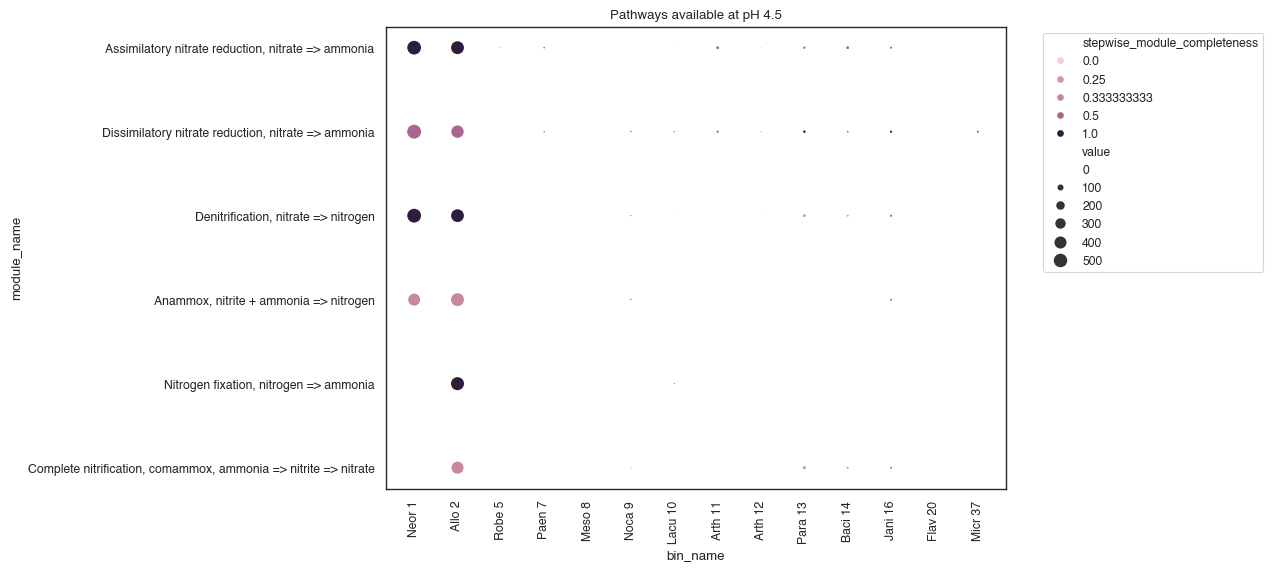

In [27]:
#Plot N pathways available at pH 4.5 only
plt.figure(figsize=(8,6))
sns.scatterplot(df_N_metabs_melt_info[df_N_metabs_melt_info['pH']==4.5],x='bin_name',y='module_name',size='value',sizes=(0,100),hue='stepwise_module_completeness')
plt.legend(bbox_to_anchor=(1.05,1))
plt.xticks(rotation=90)
plt.title('Pathways available at pH 4.5')
plt.show()

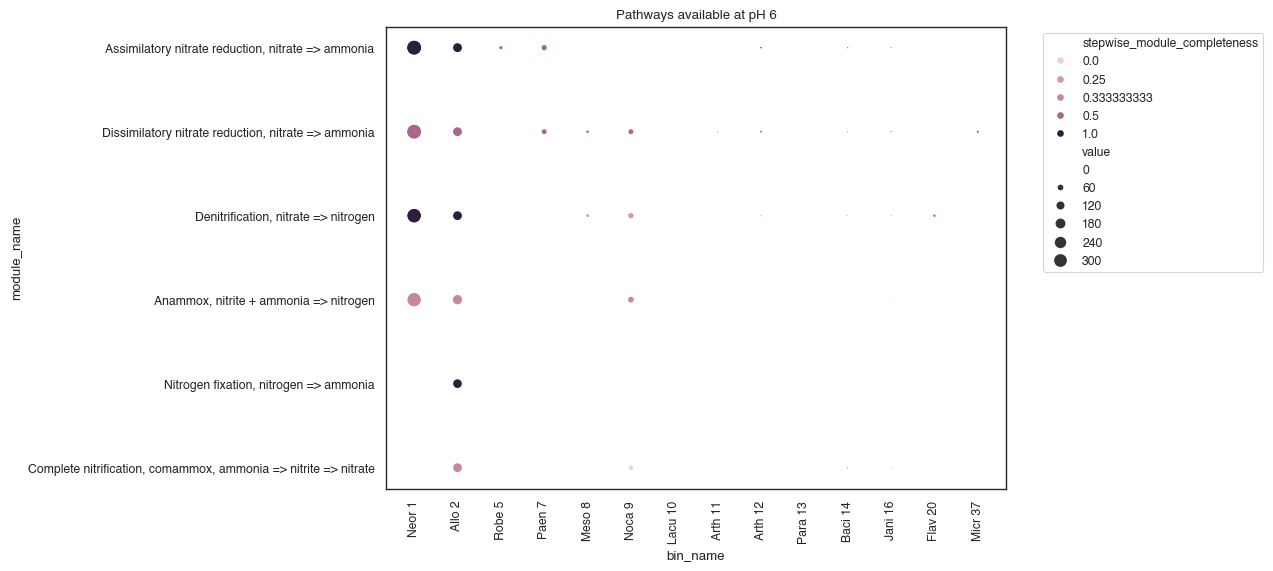

In [28]:
#Plot N pathways available at pH 6 only
plt.figure(figsize=(8,6))
sns.scatterplot(df_N_metabs_melt_info[df_N_metabs_melt_info['pH']==6],x='bin_name',y='module_name',size='value',sizes=(0,100),hue='stepwise_module_completeness')
plt.legend(bbox_to_anchor=(1.05,1))
plt.xticks(rotation=90)
plt.title('Pathways available at pH 6')
plt.show()

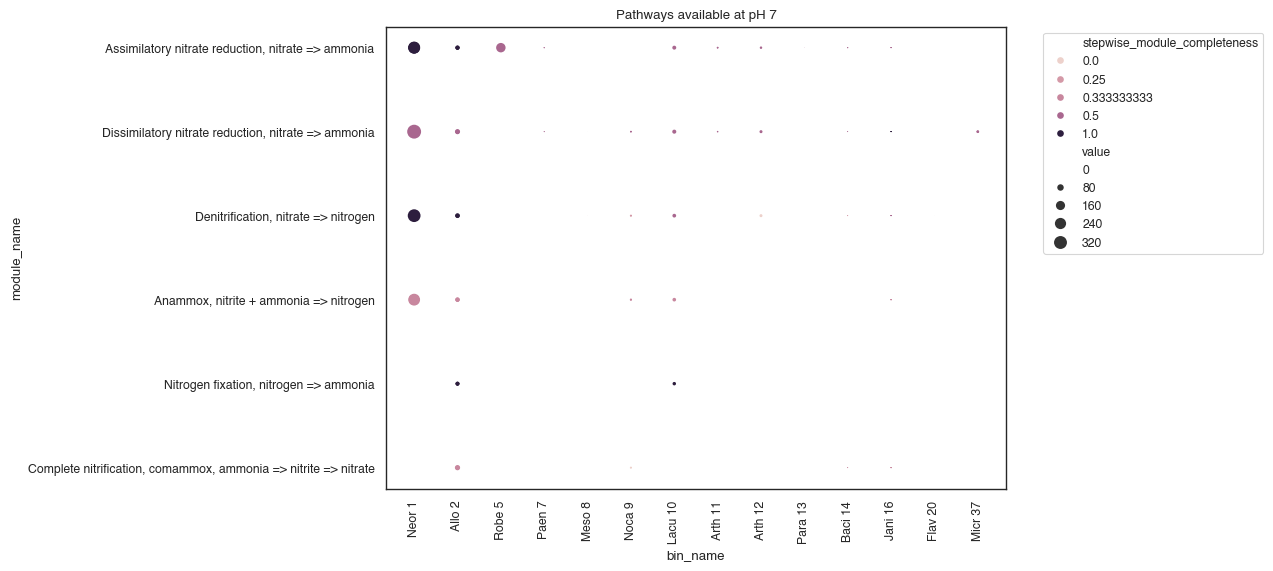

In [29]:
#Plot N pathways available at pH 7 only
plt.figure(figsize=(8,6))
sns.scatterplot(df_N_metabs_melt_info[df_N_metabs_melt_info['pH']==7],x='bin_name',y='module_name',size='value',sizes=(0,100),hue='stepwise_module_completeness')
plt.legend(bbox_to_anchor=(1.05,1))
plt.xticks(rotation=90)
plt.title('Pathways available at pH 7')
plt.show()

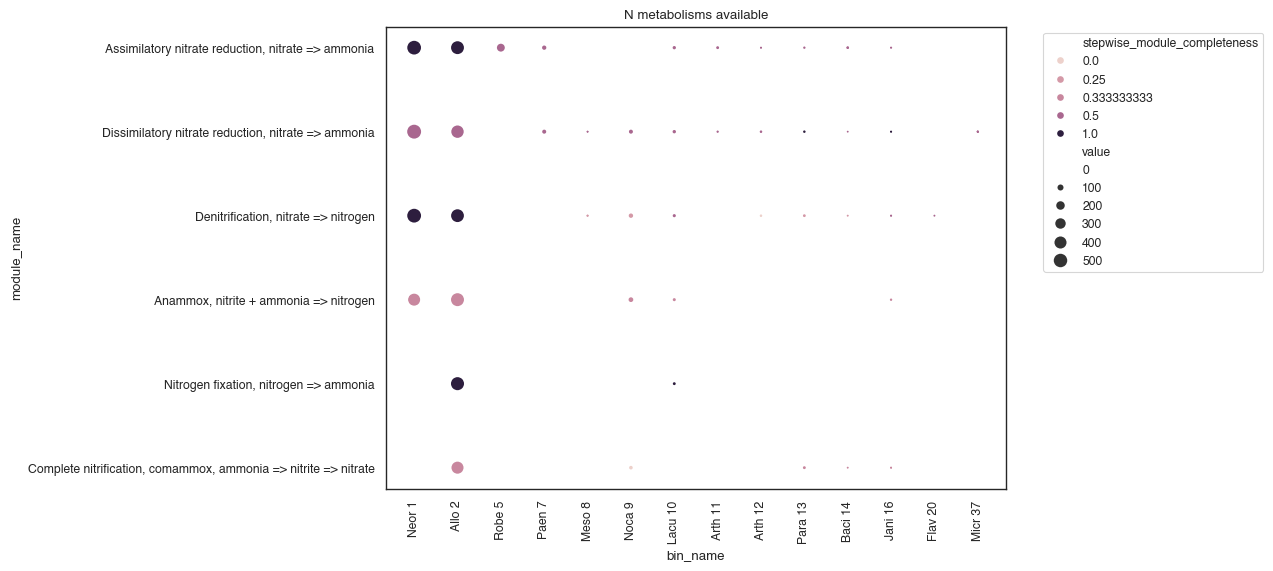

In [30]:
#Plot N pathways available across all samples
plt.figure(figsize=(8,6))
sns.scatterplot(df_N_metabs_melt_info,x='bin_name',y='module_name',size='value',sizes=(0,100),hue='stepwise_module_completeness')
plt.legend(bbox_to_anchor=(1.05,1))
plt.xticks(rotation=90)
plt.title('N metabolisms available')
plt.show()

In [31]:
#Convert the data on pathway completeness to a matrix for better plotting
df_bin_metab = df_bin_metab_estimates[['bin_name','module_name','stepwise_module_completeness']].pivot(columns='module_name',index='bin_name',values='stepwise_module_completeness').fillna(0).T[[bin_label_rename_dict[i] for i in good_bin_list]]
df_bin_metab = df_bin_metab[df_bin_metab>0].dropna(axis=0,thresh=2) #Drop metabolisms that are 0 for every MAG and set the rest of the zeroes to nans
df_bin_metab

bin_name,Neor 1,Allo 2,Lysi 3,Robe 5,Paen 7,Meso 8,Noca 9,Lacu 10,Arth 11,Arth 12,Para 13,Baci 14,Jani 16,Flav 20,Fict 21,Micr 37
module_name,,,,,,,,,,,,,,,,
3-Hydroxypropionate bi-cycle,0.384615,0.384615,0.384615,0.307692,0.153846,0.384615,0.384615,0.384615,0.076923,0.076923,0.153846,0.230769,0.538462,0.384615,0.384615,0.153846
ADP-L-glycero-D-manno-heptose biosynthesis,NaN,NaN,0.200000,NaN,0.800000,0.200000,NaN,0.800000,NaN,NaN,1.000000,NaN,0.400000,1.000000,0.200000,NaN
Acetogen,0.500000,0.500000,NaN,0.500000,NaN,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,NaN,NaN,0.500000,0.500000
Acylglycerol degradation,NaN,NaN,0.500000,NaN,NaN,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,NaN,NaN,NaN
"Adenine ribonucleotide biosynthesis, IMP => ADP,ATP",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.750000,0.750000,0.750000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"beta-Oxidation, acyl-CoA synthesis",1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,1.000000
"beta-Oxidation, peroxisome, VLCFA",NaN,NaN,NaN,NaN,0.333333,NaN,0.333333,NaN,0.333333,0.333333,NaN,NaN,0.333333,NaN,NaN,0.333333
dTDP-L-mycarose biosynthesis,NaN,NaN,NaN,NaN,0.200000,NaN,NaN,NaN,NaN,0.200000,NaN,NaN,NaN,NaN,NaN,NaN


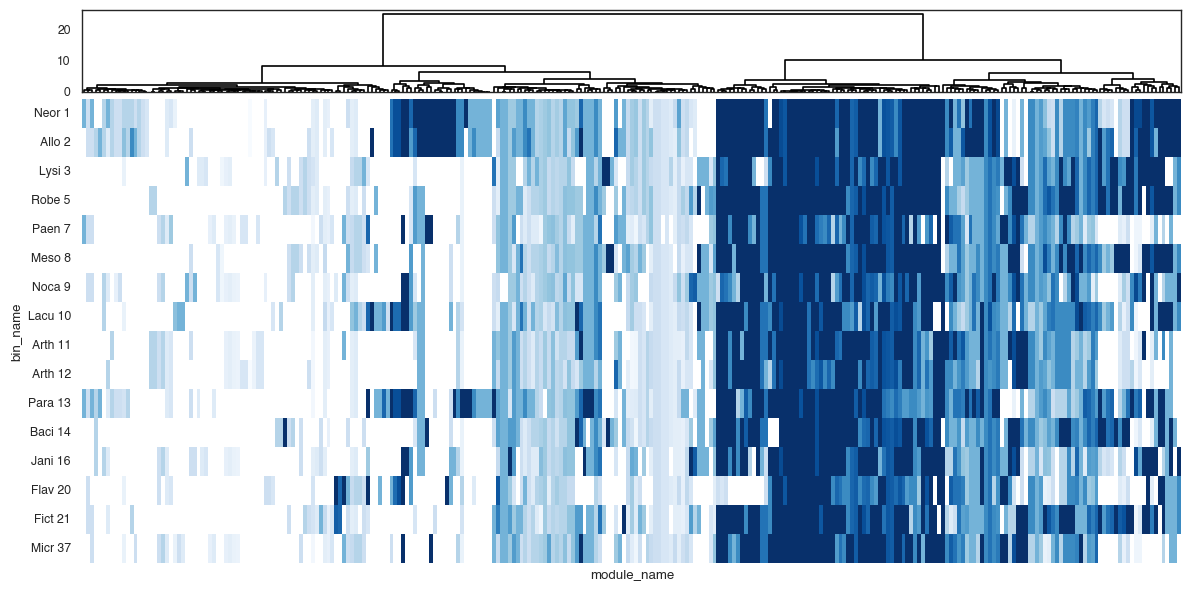

In [32]:
#Let's do a custom clustering of the metabolism df to make the order consistent
#Use scipy clustering and dendrogram visualization

#Make a copy of the df to cluster
X = df_bin_metab.fillna(0).copy(deep=True)
#Run Ward clustering on the df
Z = linkage(X,method='ward')

#Set up the plot
fig,ax = plt.subplots(nrows=2,figsize=(12,6),height_ratios=(0.15,0.85))
dn = dendrogram(Z,orientation='top',no_labels=True,color_threshold=0,above_threshold_color='black',ax=ax[0]) #create the dendrogram and color the branches at a certain level

#get the order of the leaves to reindex the df for the heatmap
dendrogram_order = dn['leaves']
clust_order = [df_bin_metab.index[i] for i in dendrogram_order]

#reindex the df_bin_metab based on the Ward clustering
df_bin_metab = df_bin_metab.reindex(clust_order)

#Now plot the completeness matrix as a heatmap
sns.heatmap(df_bin_metab[[bin_label_rename_dict[i] for i in good_bin_list]].T,cmap='Blues',cbar=False,xticklabels=False,ax=ax[1])
plt.tight_layout(h_pad=0)
plt.show()

In [33]:
#Create an IO matrix where we keep only complete pathways as 1 and set all others (including incomplete) to 0
#This will mostly be used for counting the number of complete pathways available to a bin
df_bin_metab_io = df_bin_metab.copy()
df_bin_metab_io[df_bin_metab_io!=1] = 0
df_bin_metab_io

bin_name,Neor 1,Allo 2,Lysi 3,Robe 5,Paen 7,Meso 8,Noca 9,Lacu 10,Arth 11,Arth 12,Para 13,Baci 14,Jani 16,Flav 20,Fict 21,Micr 37
module_name,,,,,,,,,,,,,,,,
"D-Arginine racemization, D-arginine => L-arginine",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"Catechol ortho-cleavage, catechol => 3-oxoadipate",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"GABA biosynthesis, prokaryotes, putrescine => GABA",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"Complete nitrification, comammox, ammonia => nitrite => nitrate",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Lactosylceramide biosynthesis,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Phosphatidylethanolamine (PE) biosynthesis, PA => PS => PE",1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0
"CAM (Crassulacean acid metabolism), light",1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"Glycogen biosynthesis, glucose-1P => glycogen/starch",1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


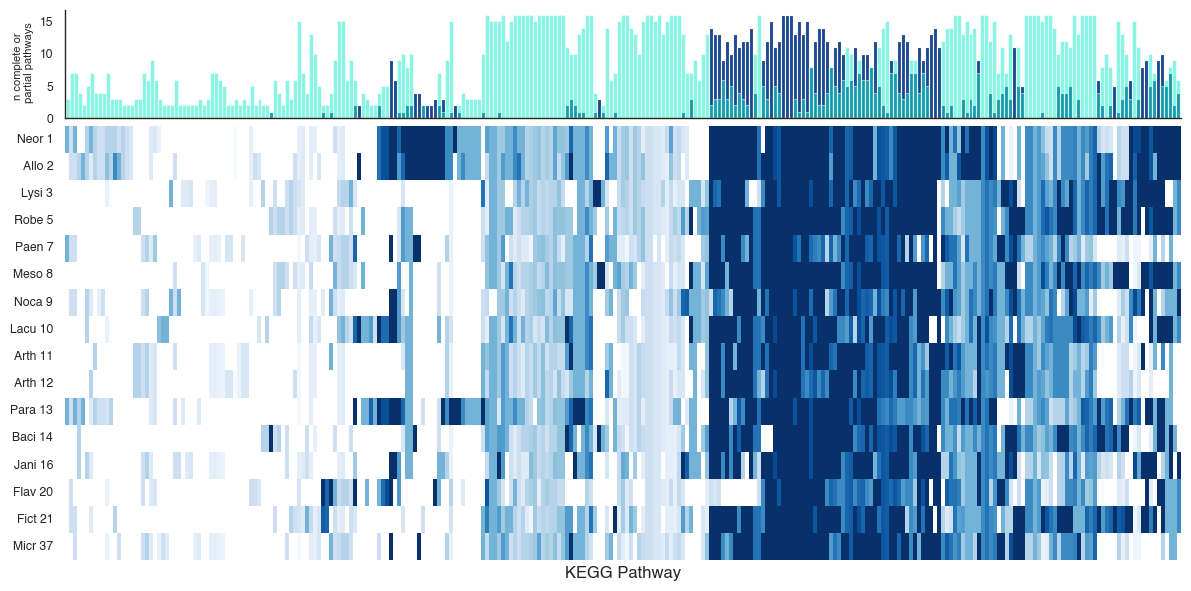

In [34]:
#Start to put this data together to visualize complete and partial pathways across all the MAGs
fig,ax = plt.subplots(nrows=2,figsize=(12,6),height_ratios=[0.25,1],sharex=False)

df_bin_metab_io.sum(axis=1).plot(kind='bar',color='xkcd:cobalt',alpha=1,width=1,figsize=(12,6),ax=ax[0]) #number of complete pathways

#To count only partial pathways, we keep only values <1 (and greater than 0, replaced above) and count how many numeric values are left
df_bin_metab[df_bin_metab<1].count(axis=1,numeric_only=True).T.plot(kind='bar',width=1,color='xkcd:aqua',alpha=0.5,figsize=(12,6),ax=ax[0]) #number of partial pathways
ax[0].set_xticks([])
ax[0].set_xlabel('')
ax[0].set_ylabel('n complete or \n partial pathways',fontsize=8)
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

sns.heatmap(df_bin_metab[[bin_label_rename_dict[i] for i in good_bin_list]].T,cmap='Blues',cbar=False,ax=ax[1]) #heatmap of complete and partial pathways
ax[1].set_xlabel('KEGG Pathway',fontsize=12)
ax[1].set_xticks([])
ax[1].set_ylabel('')
ax[1].set_yticklabels([bin_label_rename_dict[i] for i in good_bin_list])

plt.tight_layout(h_pad=0)
plt.show()


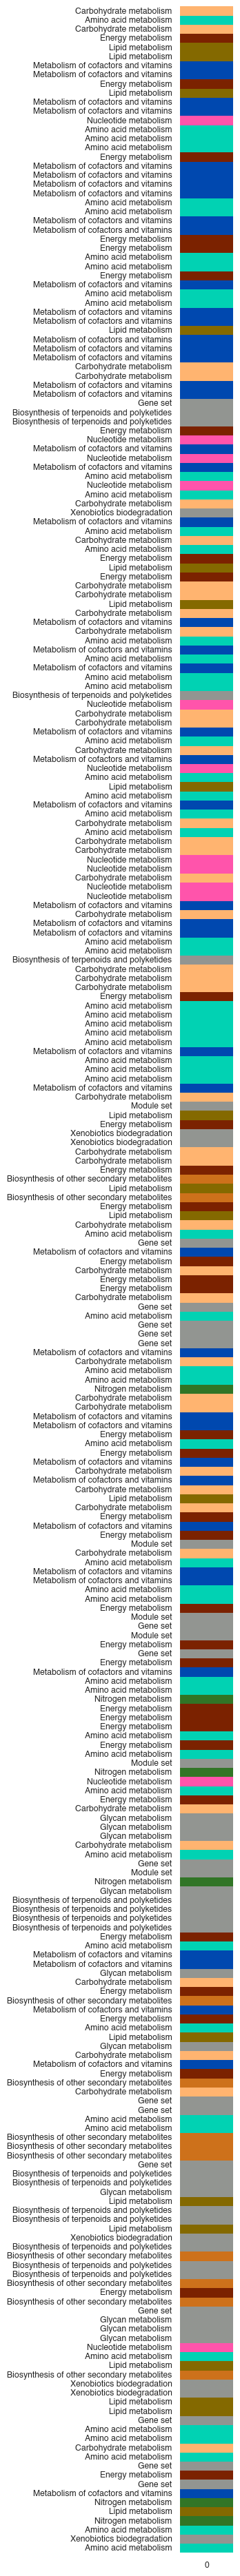

In [35]:
#Create a dictionary for mapping each pathway to a subcategory to make figure labelling easier (might subset further to categories of interest)
pathway_subcat_dict = dict(zip(df_bin_metab_estimates['module_name'],df_bin_metab_estimates['module_subcategory']))

subcat_cat_dict = dict(zip(df_bin_metab_estimates['module_subcategory'],df_bin_metab_estimates['module_category']))

#label each pathway in order for the sorted dataframe with its subcategory
bin_metab_index_subcats = [pathway_subcat_dict[i] for i in df_bin_metab.index]
#label each pathway in order for the sorted dataframe with its category, except use subcat "Nitrogen metabolism" instead of "Energy metabolism" for those pathways
bin_metab_index_cats = []
for i in bin_metab_index_subcats:
    if i == 'Nitrogen metabolism':
        bin_metab_index_cats.append('Nitrogen metabolism')
    else:
        bin_metab_index_cats.append(subcat_cat_dict[i])

pathway_subcat_number_dict = {} #assign a unique number to each subcategory so that we can plot them as a heatmap
for i in range(len(set(bin_metab_index_cats))):
    pathway_subcat_number_dict[list(set(bin_metab_index_cats))[i]] = i

bin_metab_index_nums = pd.DataFrame([pathway_subcat_number_dict[i] for i in bin_metab_index_cats],index=bin_metab_index_cats) #use the unique number to create an ordered list of categories

#Create a color palette for each category
cat_color_pal = {
    pathway_subcat_number_dict['Carbohydrate metabolism']:"#ffb470", #Carbohydrate metabolism
    pathway_subcat_number_dict['Metabolism of cofactors and vitamins']:"#0048af", #Metabolism of cofactors and vitamins
    pathway_subcat_number_dict['Amino acid metabolism']:"#01d2b3", #Amino acid metabolism
    pathway_subcat_number_dict['Gene set']:'#929591', #Gene set
    pathway_subcat_number_dict['Nucleotide metabolism']:'#ff54ab', #Nucleotide metabolism
    pathway_subcat_number_dict['Xenobiotics biodegradation']:'#929591', #Xenobiotics biodegradation
    pathway_subcat_number_dict['Module set']:'#929591', #Module set
    pathway_subcat_number_dict['Energy metabolism']:'#7b2200', #Energy metabolism
    pathway_subcat_number_dict['Biosynthesis of other secondary metabolites']:"#CD711B", #Biosynthesis of other secondary metabolites
    pathway_subcat_number_dict['Nitrogen metabolism']:"#317526", #Nitrogen metabolism
    pathway_subcat_number_dict['Biosynthesis of terpenoids and polyketides']:'#929591', #Biosynthesis  of terpenoids and polyketides
    pathway_subcat_number_dict['Lipid metabolism']:"#846900", #Lipid metabolism
    pathway_subcat_number_dict['Glycan metabolism']:'#929591' #Glycan metabolism
}

#Put the colors in order
cat_colors=[]
for i in range(13):
    cat_colors.append(cat_color_pal[i])

#now plot the category map to make sure it lines up in the expected order
fig,ax=plt.subplots(figsize=(1,48))
sns.heatmap(bin_metab_index_nums[::-1],cmap=cat_colors,cbar=False,xticklabels=True,ax=ax)
plt.show()

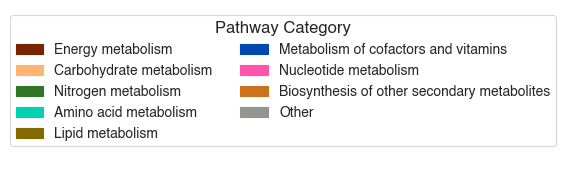

In [36]:
#Also, plot the legend on its own so we can add it to the figure
legend_handles = []
for path,num in pathway_subcat_number_dict.items():
    if path not in ['Gene set','Xenobiotics biodegradation','Module set','Biosynthesis of terpenoids and polyketides','Glycan metabolism']:
        handle = mpatches.Patch(color=cat_color_pal[num], label=f'{path}')
        legend_handles.append(handle)

legend_handles.append(mpatches.Patch(color=cat_color_pal[pathway_subcat_number_dict['Gene set']], label=f'Other'))

fig,ax = plt.subplots(figsize=(4,2))
ax.legend(handles=legend_handles,loc=1,bbox_to_anchor=(1.15,1.01),title='Pathway Category',fontsize=10,title_fontsize=12,ncols=2)
ax.axis('off')
#plt.savefig('../figs/all_metab_cat_legend.pdf',dpi=300,bbox_inches='tight')
plt.show()

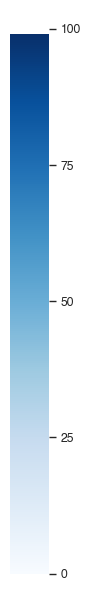

In [37]:
#This is just printing a colormap for the completeness heatmap to add to the figure
fig,ax = plt.subplots(nrows=2,figsize=(1,6),height_ratios=(0,1))
sns.heatmap(pd.DataFrame(range(100)),cmap='Blues',cbar_ax=ax[1],ax=ax[0])
ax[0].axis('off')
ax[1].set_yticks([0,25,50,75,100])
plt.tight_layout()
#plt.savefig('../figs/heatmap_legend.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [38]:
#These are all the paths available to label in the heatmap, in the order that they appear.
#The uncommented paths get labelled in the plot.
#Pathways were chosen if they were of specific interest of if they help illustrate pathways that are more or less common between the MAGs

paths_to_label = [#'D-Arginine racemization, D-arginine => L-arginine',
 #'Catechol ortho-cleavage, catechol => 3-oxoadipate',
 #'GABA biosynthesis, prokaryotes, putrescine => GABA',
 'Complete nitrification, comammox, ammonia => nitrite => nitrate',
 #'Lactosylceramide biosynthesis',
 'Anammox, nitrite + ammonia => nitrogen',
 #'Nicotinate degradation, nicotinate => fumarate',
 #'Multidrug resistance, efflux pump MexPQ-OpmE',
 #'Methanogenesis, CO2 => methane',
 #'Nodulation',
 #'Lysine degradation, bacteria, L-lysine => D-lysine => succinate',
 #'Pentose bisphosphate pathway (nucleoside degradation), archaea, nucleoside/NMP => 3-PGA/glycerone phosphate',
 #'Betaine metabolism, animals, betaine => glycine',
 #'Hydroxyproline degradation, trans-4-hydroxy-L-proline => 2-oxoglutarate',
 #'Cationic antimicrobial peptide (CAMP) resistance, protease PgtE',
 #'Sphingosine biosynthesis',
 #'Ceramide biosynthesis',
 'Xylene degradation, xylene => methylbenzoate',
 #'Toluene degradation, toluene => benzoate',
 #'beta-Oxidation, peroxisome, VLCFA',
 #'Cyclooctatin biosynthesis, dimethylallyl-PP + isopentenyl-PP => cyclooctatin',
 'Pyrimidine degradation, uracil => 3-hydroxypropanoate',
 #'Lysine degradation, lysine => saccharopine => acetoacetyl-CoA',
 #'Heparan sulfate degradation',
 #'Dermatan sulfate degradation',
 #'Chondroitin sulfate degradation',
 #'Multidrug resistance, efflux pump MexCD-OprJ',
 #'Betacyanin biosynthesis, L-tyrosine => amaranthin',
 #'F420 biosynthesis, archaea',
 #'Fosfomycin biosynthesis, phosphoenolpyruvate => fosfomycin',
 #'C-1027 beta-amino acid moiety biosynthesis, tyrosine => 3-chloro-4,5-dihydroxy-beta-phenylalanyl-PCP',
 #'Kedarcidin 2-aza-3-chloro-beta-tyrosine moiety biosynthesis, azatyrosine => 2-aza-3-chloro-beta-tyrosyl-PCP',
 #'Cephamycin C biosynthesis, aminoadipate + cycteine + valine => cephamycin C',
 #'beta-Carotene biosynthesis, GGAP => beta-carotene',
 #'Bile acid biosynthesis, cholesterol => cholate/chenodeoxycholate',
 #'Benzoate degradation, cyclohexanecarboxylic acid =>pimeloyl-CoA',
 #'Chlortetracycline biosynthesis, pretetramide => chlortetracycline',
 'Tetracycline/oxytetracycline biosynthesis, pretetramide => tetracycline/oxytetracycline',
 #'O-glycan biosynthesis, mannose type (core M3)',
 #'Jasmonic acid biosynthesis',
 #'dTDP-L-oleandrose biosynthesis',
 #'dTDP-L-mycarose biosynthesis',
 #'Monolignol biosynthesis, phenylalanine/tyrosine => monolignol',
 #'Helicobacter pylori pathogenicity signature, cagA pathogenicity island',
 #'Flavanone biosynthesis, phenylalanine => naringenin',
 #'Cremeomycin biosynthesis, aspartate/3,4-AHBA => cremeomycin',
 #'Lysine biosynthesis, AAA pathway, 2-oxoglutarate => 2-aminoadipate => lysine',
 #'Pertussis pathogenicity signature, T1SS',
 #'Catecholamine biosynthesis, tyrosine => dopamine => noradrenaline => adrenaline',
 #'Cationic antimicrobial peptide (CAMP) resistance, dltABCD operon',
 #'Pectin degradation',
 #'Kanosamine biosynthesis, glucose 6-phosphate => kanosamine',
 'Dissimilatory sulfate reduction, sulfate => H2S',
 #'Heme biosynthesis, archaea, siroheme => heme',
 #'UDP-L-FucNAm biosynthesis',
 #'Non-phosphorylative Entner-Doudoroff pathway, gluconate/galactonate => glycerate',
 #'Fatty acid elongation in mitochondria',
 #'Melatonin biosynthesis, plants, tryptophan => serotonin => melatonin',
 #'Hydroxypropionate-hydroxybutylate cycle',
 #'Thiamine biosynthesis, pyridoxal-5P => TMP/thiamine/TPP',
 #'Aerobactin biosynthesis, lysine => aerobactin',
 #'C4-dicarboxylic acid cycle, NAD - malic enzyme type',
 #'Ascorbate biosynthesis, plants, fructose-6P => ascorbate',
 #'Keratan sulfate degradation',
 #'Menaquinone biosynthesis, futalosine pathway',
 #'Menaquinone biosynthesis, modified futalosine pathway',
 #'Cysteine biosynthesis, homocysteine + serine => cysteine',
 #'Coenzyme M biosynthesis',
 #'C5 isoprenoid biosynthesis, mevalonate pathway',
 #'C5 isoprenoid biosynthesis, mevalonate pathway, archaea',
 #'C10-C20 isoprenoid biosynthesis, non-plant eukaryotes',
 #'C10-C20 isoprenoid biosynthesis, plants',
 #'ADP-L-glycero-D-manno-heptose biosynthesis',
 'Nitrogen fixation, nitrogen => ammonia',
 'Sulfate-sulfur assimilation',
 #'Multidrug resistance, efflux pump MexAB-OprM',
 #'Arginine succinyltransferase pathway, arginine => glutamate',
 #'Undecaprenylphosphate alpha-L-Ara4N biosynthesis, UDP-GlcA => undecaprenyl phosphate alpha-L-Ara4N',
 #'CMP-KDO biosynthesis',
 #'KDO2-lipid A biosynthesis, Raetz pathway, non-LpxL-LpxM type',
 #'KDO2-lipid A biosynthesis, Raetz pathway, LpxL-LpxM type',
 'Pyruvate oxidation, pyruvate => acetyl-CoA',
 #'NADH:quinone oxidoreductase, prokaryotes',
 #'Tyrosine degradation, tyrosine => homogentisate',
 'Purine degradation, xanthine => urea',
 'Nitrate assimilation',
 'Assimilatory nitrate reduction, nitrate => ammonia',
 #'Betaine biosynthesis, choline => betaine',
 'Succinate dehydrogenase, prokaryotes',
 #'Ectoine degradation, ectoine => aspartate',
 'Thiosulfate oxidation by SOX complex, thiosulfate => sulfate',
 'Cytochrome bd ubiquinol oxidase',
 'Cytochrome c oxidase, cbb3-type',
 'Denitrification, nitrate => nitrogen',
 #'Glutathione biosynthesis, glutamate => glutathione',
 #'Ubiquinone biosynthesis, prokaryotes, chorismate (+ polyprenyl-PP) => ubiquinol',
 #'Tyrosine biosynthesis, chorismate => arogenate => tyrosine',
 'Cytochrome o ubiquinol oxidase',
 #'Multidrug resistance, efflux pump MexJK-OprM',
 #'Methanofuran biosynthesis',
 'Methane oxidation, methanotroph, methane => formaldehyde',
 #'Oxygenic photosynthesis in plants and cyanobacteria',
 'Anoxygenic photosynthesis in purple bacteria',
 #'Multidrug resistance, efflux pump BpeEF-OprC',
 #'Homoprotocatechuate degradation, homoprotocatechuate => 2-oxohept-3-enedioate',
 #'Tryptophan metabolism, tryptophan => kynurenine => 2-aminomuconate',
 #'Lipoic acid biosynthesis, octanoyl-CoA => dihydrolipoyl-E2',
 #'Lipoic acid biosynthesis, eukaryotes, octanoyl-ACP => dihydrolipoyl-H',
 'Ectoine biosynthesis, aspartate => ectoine',
 #'Malonate semialdehyde pathway, propanoyl-CoA => acetyl-CoA',
 #'C4-dicarboxylic acid cycle, NADP - malic enzyme type',
 #'Acetogen',
 #'Pyridoxal-P biosynthesis, erythrose-4P => pyridoxal-P',
 #'Formaldehyde assimilation, xylulose monophosphate pathway',
 #'UDP-N-acetyl-D-glucosamine biosynthesis, eukaryotes, glucose => UDP-GlcNAc',
 'Methylaspartate cycle',
 #'Fatty acid biosynthesis in mitochondria, fungi',
 #'Tetrahydrofolate biosynthesis, mediated by PTPS, GTP => THF',
 #'Ascorbate biosynthesis, animals, glucose-1P => ascorbate',
 #'Riboflavin biosynthesis, fungi, GTP => riboflavin/FMN/FAD',
 'Dicarboxylate-hydroxybutyrate cycle',
# 'Ethylene biosynthesis, methionine => ethylene',
# 'Formaldehyde assimilation, serine pathway',
# 'Tetrahydrofolate biosynthesis, mediated by ribA and trpF, GTP => THF',
 #'Coenzyme A biosynthesis, archaea, 2-oxoisovalerate => 4-phosphopantoate => CoA',
 #'D-Glucuronate degradation, D-glucuronate => pyruvate + D-glyceraldehyde 3P',
# 'D-Galacturonate degradation (bacteria), D-galacturonate => pyruvate + D-glyceraldehyde 3P',
 'Dissimilatory nitrate reduction, nitrate => ammonia',
# 'Phenylalanine biosynthesis, chorismate => phenylpyruvate => phenylalanine',
 #'Tyrosine biosynthesis, chorismate => HPP => tyrosine',
 #'Thiamine biosynthesis, archaea, AIR (+ NAD+) => TMP/TPP',
 'Glycogen degradation, glycogen => glucose-6P',
 #'Vancomycin resistance, D-Ala-D-Ser type',
 #'Multidrug resistance, efflux pump AbcA',
 #'Multidrug resistance, efflux pump NorB',
 #'Lysine degradation, bacteria, L-lysine => glutarate => succinate/acetyl-CoA',
 #'Multidrug resistance, efflux pump QacA',
 'Pentose phosphate pathway, archaea, fructose 6P => ribose 5P',
 #'Incomplete reductive citrate cycle, acetyl-CoA => oxoglutarate',
 'Ethylmalonyl pathway',
 '3-Hydroxypropionate bi-cycle',
 #'Thiamine biosynthesis, plants, AIR (+ NAD+) => TMP/thiamine/TPP',
 #'C4-dicarboxylic acid cycle, phosphoenolpyruvate carboxykinase type',
 #'Cationic antimicrobial peptide (CAMP) resistance, lysyl-phosphatidylglycerol (L-PG) synthase MprF',
 #'Lysine degradation, bacteria, L-lysine => succinate',
 #'Inositol phosphate metabolism, Ins(1,3,4,5)P4 => Ins(1,3,4)P3 => myo-inositol',
 #'Triacylglycerol biosynthesis',
 #'Mugineic acid biosynthesis, methionine => 3-epihydroxymugineic acid',
 #'Methanogenesis, acetate => methane',
 #'Fatty acid biosynthesis in mitochondria, animals',
 #'Pyocyanine biosynthesis, chorismate => pyocyanine',
 'Reductive acetyl-CoA pathway (Wood-Ljungdahl pathway)',
 #'Glucuronate pathway (uronate pathway)',
 #'Photorespiration',
 #'Catechol meta-cleavage, catechol => acetyl-CoA / 4-methylcatechol => propanoyl-CoA',
 #'Trans-cinnamate degradation, trans-cinnamate => acetyl-CoA',
 'Assimilatory sulfate reduction, sulfate => H2S',
 #'Acylglycerol degradation',
 'Anoxygenic photosynthesis in green sulfur bacteria',
 #'Ascorbate degradation, ascorbate => D-xylulose-5P',
 #'Phylloquinone biosynthesis, chorismate (+ phytyl-PP) => phylloquinol',
 #'Ornithine biosynthesis, glutamate => ornithine',
 #'Valine/isoleucine biosynthesis, pyruvate => valine / 2-oxobutanoate => isoleucine',
 #'Isoleucine biosynthesis, threonine => 2-oxobutanoate => isoleucine',
 'Proline biosynthesis, glutamate => proline',
 #'Molybdenum cofactor biosynthesis, GTP => molybdenum cofactor',
 #'Tryptophan biosynthesis, chorismate => tryptophan',
 'Cysteine biosynthesis, serine => cysteine',
 #'Histidine biosynthesis, PRPP => histidine',
 #'Leucine biosynthesis, 2-oxoisovalerate => 2-oxoisocaproate',
 #'Phosphate acetyltransferase-acetate kinase pathway, acetyl-CoA => acetate',
 #'Pentose phosphate pathway, oxidative phase, glucose 6P => ribulose 5P',
 'Entner-Doudoroff pathway, glucose-6P => glyceraldehyde-3P + pyruvate',
 #'Semi-phosphorylative Entner-Doudoroff pathway, gluconate => glycerate-3P',
 #'dTDP-L-rhamnose biosynthesis',
 #'Proline degradation, proline => glutamate',
 #'Histidine degradation, histidine => N-formiminoglutamate => glutamate',
 'Riboflavin biosynthesis, plants and bacteria, GTP => riboflavin/FMN/FAD',
 'Heme biosynthesis, plants and bacteria, glutamate => heme',
 #'Guanine ribonucleotide biosynthesis, IMP => GDP,GTP',
 'Coenzyme A biosynthesis, pantothenate => CoA',
 #'PRPP biosynthesis, ribose 5P => PRPP',
 'Pentose phosphate pathway, non-oxidative phase, fructose 6P => ribose 5P',
# 'De novo purine biosynthesis, PRPP + glutamine => IMP',
 #'Pyrimidine ribonucleotide biosynthesis, UMP => UDP/UTP,CDP/CTP',
# 'Adenine ribonucleotide biosynthesis, IMP => ADP,ATP',
 'Glycolysis (Embden-Meyerhof pathway), glucose => pyruvate',
 'Gluconeogenesis, oxaloacetate => fructose-6P',
# 'Glycine cleavage system',
# 'Glycolysis, core module involving three-carbon compounds',
# 'Arginine biosynthesis, ornithine => arginine',
 #'Pantothenate biosynthesis, valine/L-aspartate => pantothenate',
 #'beta-Oxidation',
 'Shikimate pathway, phosphoenolpyruvate + erythrose-4P => chorismate',
# 'Serine biosynthesis, glycerate-3P => serine',
# 'Siroheme biosynthesis, glutamyl-tRNA => siroheme',
# 'Pyrimidine deoxyribonucleotide biosynthesis, UDP => dTTP',
 'Nucleotide sugar biosynthesis, glucose => UDP-glucose',
# 'NAD biosynthesis, aspartate => quinolinate => NAD',
# 'Lysine biosynthesis, succinyl-DAP pathway, aspartate => lysine',
 'Pentose phosphate pathway (Pentose phosphate cycle)',
 #'UDP-N-acetyl-D-glucosamine biosynthesis, prokaryotes, glucose => UDP-GlcNAc',
 'Deoxyribonucleotide biosynthesis, ADP/GDP/CDP/UDP => dATP/dGTP/dCTP/dUTP',
 #'C5 isoprenoid biosynthesis, non-mevalonate pathway',
# 'Lysine biosynthesis, DAP aminotransferase pathway, aspartate => lysine',
# 'Lysine biosynthesis, DAP dehydrogenase pathway, aspartate => lysine',
 #'Heme biosynthesis, bacteria, glutamyl-tRNA => coproporphyrin III => heme',
# 'Methionine biosynthesis, aspartate => homoserine => methionine',
 #'Threonine biosynthesis, aspartate => homoserine => threonine',
 #'Tetrahydrofolate biosynthesis, GTP => THF',
 #'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Glyoxylate cycle',
# 'C1-unit interconversion, prokaryotes',
# 'Fatty acid biosynthesis, initiation',
# 'Citrate cycle, second carbon oxidation, 2-oxoglutarate => oxaloacetate',
 'Citrate cycle (TCA cycle, Krebs cycle)',
# 'beta-Oxidation, acyl-CoA synthesis',
 'Cytochrome bc1 complex respiratory unit',
 'Cytochrome c oxidase, prokaryotes',
 'GABA (gamma-Aminobutyrate) shunt',
# 'Trehalose biosynthesis, D-glucose 1P => trehalose',
# 'Methionine degradation',
 'NAD biosynthesis, tryptophan => quinolinate => NAD',
 #'Phenylacetate degradation, phenylaxetate => acetyl-CoA/succinyl-CoA',
# 'D-galactonate degradation, De Ley-Doudoroff pathway, D-galactonate => glycerate-3P',
# 'Betaine degradation, bacteria, betaine => pyruvate',
 #'Guanine ribonucleotide degradation, GMP => Urate',
# 'Leucine degradation, leucine => acetoacetate + acetyl-CoA',
 #'Lipoic acid biosynthesis, plants and bacteria, octanoyl-ACP => dihydrolipoyl-E2/H',
# 'Heme biosynthesis, animals and fungi, glycine => heme',
# 'De novo pyrimidine biosynthesis, glutamine (+ PRPP) => UMP',
# 'Adenine ribonucleotide degradation, AMP => Urate',
 'Reductive pentose phosphate cycle (Calvin cycle)',
 #'C10-C20 isoprenoid biosynthesis, bacteria',
 #'C10-C20 isoprenoid biosynthesis, archaea',
 #'beta-Lactam resistance, Bla system',
 #'Pyridoxal-P biosynthesis, R5P + glyceraldehyde-3P + glutamine => pyridoxal-P',
 #'Menaquinone biosynthesis, chorismate (+ polyprenyl-PP) => menaquinol',
 'Nucleotide sugar biosynthesis, galactose => UDP-galactose',
 #'Galactose degradation, Leloir pathway, galactose => alpha-D-glucose-1P',
# 'L-threo-Tetrahydrobiopterin biosynthesis, GTP => L-threo-BH4',
# 'Tetrahydrobiopterin biosynthesis, GTP => BH4',
 #'C1-unit interconversion, eukaryotes',
 #'Ketone body biosynthesis, acetyl-CoA => acetoacetate/3-hydroxybutyrate/acetone',
 #'Thiamine biosynthesis, prokaryotes, AIR (+ DXP/glycine) => TMP/TPP',
 #'Thiamine biosynthesis, prokaryotes, AIR (+ DXP/tyrosine) => TMP/TPP',
 #'GABA biosynthesis, eukaryotes, putrescine => GABA',
 #'Isoleucine biosynthesis, pyruvate => 2-oxobutanoate',
 #'Lipoic acid biosynthesis, animals and bacteria, octanoyl-ACP => dihydrolipoyl-H => dihydrolipoyl-E2',
 #'Lysine biosynthesis, acetyl-DAP pathway, aspartate => lysine',
 #'Formaldehyde assimilation, ribulose monophosphate pathway',
 #'Proline metabolism',
 'Reductive citrate cycle (Arnon-Buchanan cycle)',
 #'CAM (Crassulacean acid metabolism), dark',
 #'Pimeloyl-ACP biosynthesis, BioC-BioH pathway, malonyl-ACP => pimeloyl-ACP',
 #'Pantothenate biosynthesis, 2-oxoisovalerate/spermine => pantothenate',
 #'Arginine biosynthesis, glutamate => acetylcitrulline => arginine',
 'Urea cycle',
 #'Biotin biosynthesis, pimeloyl-ACP/CoA => biotin',
 #'Biotin biosynthesis, BioI pathway, long-chain-acyl-ACP => pimeloyl-ACP => biotin',
 #'Biotin biosynthesis, BioW pathway, pimelate => pimeloyl-CoA => biotin',
 #'Biotin biosynthesis, BioU pathway, pimeloyl-ACP/CoA => biotin',
 'Cytochrome aa3-600 menaquinol oxidase',
 #'Cysteine biosynthesis, methionine => cysteine',
 #'Polyamine biosynthesis, arginine => agmatine => putrescine => spermidine',
 #'Methionine salvage pathway',
 #'Pyrimidine degradation, uracil => beta-alanine, thymine => 3-aminoisobutanoate',
 #'Cobalamin biosynthesis, anaerobic, uroporphyrinogen III => sirohydrochlorin => cobyrinate a,c-diamide',
 #'Cobalamin biosynthesis, aerobic, uroporphyrinogen III => precorrin 2 => cobyrinate a,c-diamide',
 #'Phosphatidylcholine (PC) biosynthesis, PE => PC',
 'F-type ATPase, prokaryotes and chloroplasts',
 #'Thiamine salvage pathway, HMP/HET => TMP',
 'Cobalamin biosynthesis, cobyrinate a,c-diamide => cobalamin',
 #'Phosphatidylethanolamine (PE) biosynthesis, PA => PS => PE',
 #'Fatty acid biosynthesis, elongation',
 'Glycogen biosynthesis, glucose-1P => glycogen/starch',
 #'CAM (Crassulacean acid metabolism), light',
 #'Propanoyl-CoA metabolism, propanoyl-CoA => succinyl-CoA',
 #'Polyamine biosynthesis, arginine => ornithine => putrescine'
 ]

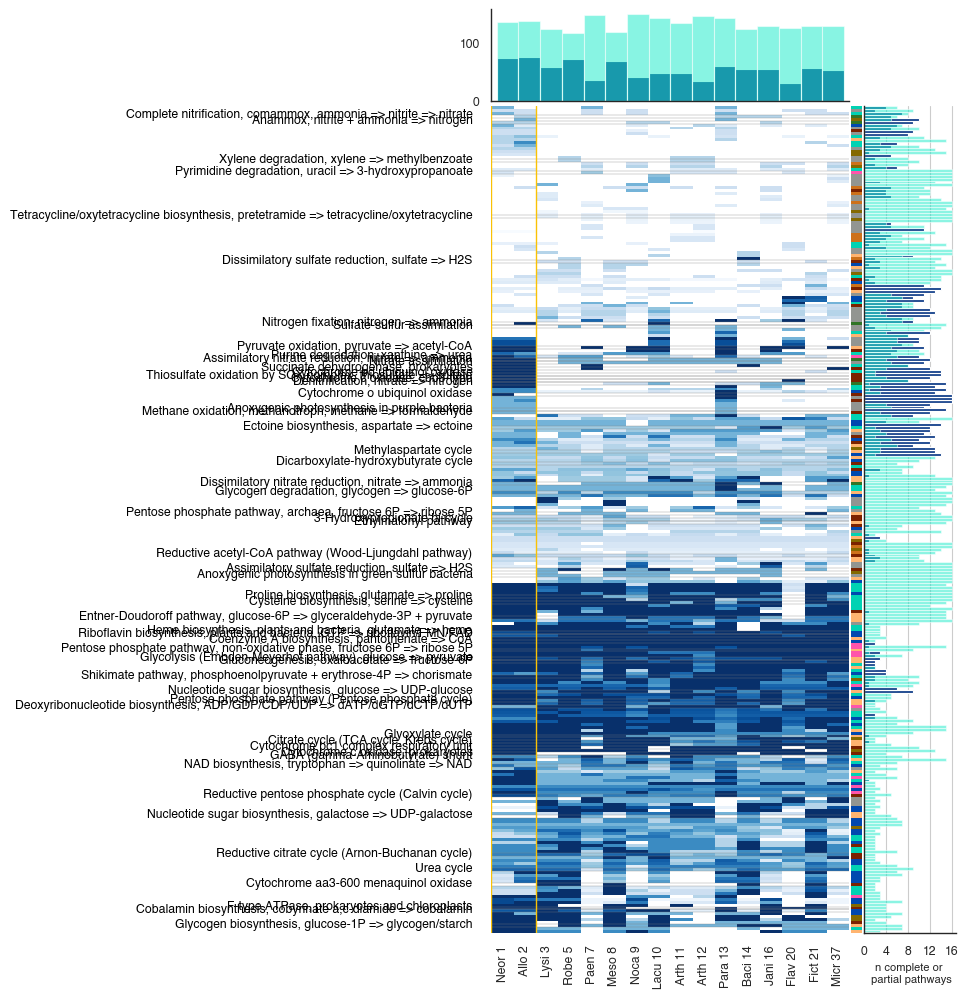

In [39]:
#This is the figure that appears in the paper, showing pathway completeness along with counts of (partial and complete) pathways for each MAG and the number of MAGs encoding each pathway

sns.set_style('white')
mpl.rcParams['font.family'] = 'Helvetica'
mpl.rcParams['pdf.fonttype'] = 42
fig,ax = plt.subplots(nrows=2,ncols=3,figsize=(6,12),width_ratios=[0.775,0.025,0.2],height_ratios=[0.1,0.9],sharey=False)

df_bin_metab_io.sum(axis=0).plot(kind='bar',color='xkcd:cobalt',alpha=1,width=1,ax=ax[0,0]) #number of complete pathways
df_bin_metab.replace({1:np.nan}).count().plot(kind='bar',width=1,color='xkcd:aqua',alpha=0.5,ax=ax[0,0]) #number of partial pathways

ax[0,0].set_xticks([])
ax[0,0].set_xlabel('')
ax[0,0].spines['top'].set_visible(False)
ax[0,0].spines['right'].set_visible(False)
ax[0,0].margins(x=0)

ax[0,1].axis('off')
ax[0,2].axis('off')

path_tick_labels = []
for i in df_bin_metab.index:
    if i in paths_to_label:
        path_tick_labels.append(i)
    else:
        path_tick_labels.append('')

sns.heatmap(df_bin_metab[[bin_label_rename_dict[i] for i in good_bin_list]],cmap='Blues',cbar=False,ax=ax[1,0]) #heatmap of complete and partial pathways

for i in [i for i in range(len(path_tick_labels)) if path_tick_labels[i] != '']:
    ax[1,0].axhline(i,linewidth=0.25,linestyle='-',color='gray')
    ax[1,0].axhline(i+1,linewidth=0.25,linestyle='-',color='gray')

ax[1,0].axvline(0,linewidth=1,linestyle='-',color='xkcd:goldenrod')
ax[1,0].axvline(2,linewidth=1,linestyle='-',color='xkcd:goldenrod')

ax[1,0].set_xlabel('',fontsize=12)

ax[1,0].set_ylabel('')
ax[1,0].set_xticklabels([bin_label_rename_dict[i] for i in good_bin_list])

sns.heatmap(bin_metab_index_nums,cmap=cat_colors,cbar=False,yticklabels=False,ax=ax[1,1])
ax[1,1].set_xlabel('')
ax[1,1].set_xticks([])

sns.set_style('whitegrid')
df_bin_metab_io.sum(axis=1).plot(kind='barh',color='xkcd:cobalt',alpha=1,width=1,ax=ax[1,2]) #number of complete pathways
df_bin_metab[df_bin_metab.sum(axis=1)<17][df_bin_metab[df_bin_metab.sum(axis=1)<17]<1].count(axis=1,numeric_only=True).T.plot(kind='barh',width=1,color='xkcd:aqua',alpha=0.5,ax=ax[1,2]) #number of partial pathways
ax[1,2].set_yticks([])
ax[1,2].set_xticks([0,4,8,12,16])
ax[1,2].set_xlabel('n complete or \n partial pathways',fontsize=8)
ax[1,2].set_ylabel('')
ax[1,2].spines['top'].set_visible(False)
ax[1,2].spines['right'].set_visible(False)

ax[1,0].set_yticks(range(len(df_bin_metab.index)))
ax[1,0].set_yticklabels(path_tick_labels)
ax[1,0].tick_params(axis='y',direction='out',length=10,width=10,colors='black')

plt.subplots_adjust(wspace=0.01,hspace=0.01)
#plt.tight_layout(h_pad=0)
#plt.savefig('../figs/all_metab_completeness_A.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [40]:
#Number of partial metabolic pathways for each MAG
df_bin_metab.replace({1:np.nan}).count()

bin_name
Neor 1     137
Allo 2     138
Lysi 3     124
Robe 5     118
Paen 7     149
Meso 8     120
Noca 9     151
Lacu 10    143
Arth 11    134
Arth 12    146
Para 13    143
Baci 14    124
Jani 16    130
Flav 20    127
Fict 21    130
Micr 37    130
dtype: int64

In [41]:
#Number of complete metabolic pathways for each MAG
df_bin_metab_io.sum()

bin_name
Neor 1     75.0
Allo 2     77.0
Lysi 3     59.0
Robe 5     72.0
Paen 7     37.0
Meso 8     69.0
Noca 9     42.0
Lacu 10    49.0
Arth 11    48.0
Arth 12    35.0
Para 13    60.0
Baci 14    55.0
Jani 16    55.0
Flav 20    31.0
Fict 21    57.0
Micr 37    54.0
dtype: float64

In [42]:
def find_shared_paths(bin_i=None,bin_j=None,complete=True):
    """Create list of pathways that are shared by two bins/MAGs. 
    If complete==True, return complete pathways only. 
    Return complete and partials if complete==False.
    Specify bin by name, e.g., 'Neor 1', etc."""
    
    if bin_i not in [bin_label_rename_dict[i] for i in good_bin_list] or bin_j not in [bin_label_rename_dict[i] for i in good_bin_list]:
        raise ValueError(f'Please specify a pair of bins that are both in the good bin list:{[bin_label_rename_dict[i] for i in good_bin_list]}')

    if complete==True:
        bin_i_complete_path_list = df_bin_metab[bin_i][df_bin_metab[bin_i]==1].index.to_list() #list of 100% complete paths; the values here are completeness scores (0-1)
        bin_j_complete_path_list = df_bin_metab[bin_j][df_bin_metab[bin_j]==1].index.to_list()
        shared_paths = list(set(bin_i_complete_path_list)&set(bin_j_complete_path_list)) #get the intersection of the complete pathways between the two bins
    elif complete==False:
        bin_i_path_list = df_bin_metab[bin_i][df_bin_metab[bin_i]>0].index.to_list() #list of complete and partially complete paths
        bin_j_path_list = df_bin_metab[bin_j][df_bin_metab[bin_j]>0].index.to_list()
        shared_paths = list(set(bin_i_path_list)&set(bin_j_path_list)) #get the intersection of the complete pathways between the two bins
    else:
        raise ValueError("'complete' variable must be True or False")
    
    print(f'{len(shared_paths)} metabolic pathways shared by {bin_i} and {bin_j}.')

    return shared_paths

find_shared_paths(bin_i='Neor 1',bin_j='Allo 2',complete=True)

71 metabolic pathways shared by Neor 1 and Allo 2.


['Serine biosynthesis, glycerate-3P => serine',
 'Leucine biosynthesis, 2-oxoisovalerate => 2-oxoisocaproate',
 'Threonine biosynthesis, aspartate => homoserine => threonine',
 'Polyamine biosynthesis, arginine => ornithine => putrescine',
 'Thiosulfate oxidation by SOX complex, thiosulfate => sulfate',
 'Ornithine biosynthesis, glutamate => ornithine',
 'Cytochrome c oxidase, prokaryotes',
 'Tryptophan biosynthesis, chorismate => tryptophan',
 'Pentose phosphate pathway (Pentose phosphate cycle)',
 'Arginine biosynthesis, ornithine => arginine',
 'beta-Oxidation',
 'Proline degradation, proline => glutamate',
 'C1-unit interconversion, prokaryotes',
 'Nucleotide sugar biosynthesis, glucose => UDP-glucose',
 'Glycolysis (Embden-Meyerhof pathway), glucose => pyruvate',
 'Phosphate acetyltransferase-acetate kinase pathway, acetyl-CoA => acetate',
 'Nitrate assimilation',
 'Assimilatory nitrate reduction, nitrate => ammonia',
 'Cytochrome bd ubiquinol oxidase',
 'Denitrification, nitrate 

In [43]:
find_shared_paths(bin_i='Neor 1',bin_j='Lysi 3',complete=True)

40 metabolic pathways shared by Neor 1 and Lysi 3.


['Serine biosynthesis, glycerate-3P => serine',
 'Leucine biosynthesis, 2-oxoisovalerate => 2-oxoisocaproate',
 'Threonine biosynthesis, aspartate => homoserine => threonine',
 'Ornithine biosynthesis, glutamate => ornithine',
 'Tryptophan biosynthesis, chorismate => tryptophan',
 'Arginine biosynthesis, ornithine => arginine',
 'beta-Oxidation',
 'C1-unit interconversion, prokaryotes',
 'Gluconeogenesis, oxaloacetate => fructose-6P',
 'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Pyrimidine degradation, uracil => beta-alanine, thymine => 3-aminoisobutanoate',
 'Glycine cleavage system',
 'Phosphatidylcholine (PC) biosynthesis, PE => PC',
 'Shikimate pathway, phosphoenolpyruvate + erythrose-4P => chorismate',
 'Coenzyme A biosynthesis, pantothenate => CoA',
 'Fatty acid biosynthesis, initiation',
 'Fatty acid biosynthesis, elongation',
 'Citrate cycle (TCA cycle, Krebs cycle)',
 'Cysteine biosynthesis, serine => cysteine',
 'Phosphatidylethanolamine (PE) bi

In [44]:
find_shared_paths(bin_i='Allo 2',bin_j='Lysi 3',complete=True)

41 metabolic pathways shared by Allo 2 and Lysi 3.


['Serine biosynthesis, glycerate-3P => serine',
 'Leucine biosynthesis, 2-oxoisovalerate => 2-oxoisocaproate',
 'Threonine biosynthesis, aspartate => homoserine => threonine',
 'Ornithine biosynthesis, glutamate => ornithine',
 'Tryptophan biosynthesis, chorismate => tryptophan',
 'Arginine biosynthesis, ornithine => arginine',
 'beta-Oxidation',
 'C1-unit interconversion, prokaryotes',
 'Gluconeogenesis, oxaloacetate => fructose-6P',
 'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Pyrimidine degradation, uracil => beta-alanine, thymine => 3-aminoisobutanoate',
 'Glycine cleavage system',
 'Phosphatidylcholine (PC) biosynthesis, PE => PC',
 'Shikimate pathway, phosphoenolpyruvate + erythrose-4P => chorismate',
 'Coenzyme A biosynthesis, pantothenate => CoA',
 'Fatty acid biosynthesis, initiation',
 'Fatty acid biosynthesis, elongation',
 'Citrate cycle (TCA cycle, Krebs cycle)',
 'Cysteine biosynthesis, serine => cysteine',
 'Phosphatidylethanolamine (PE) bi

In [45]:
find_shared_paths(bin_i='Lysi 3',bin_j='Robe 5',complete=True)

49 metabolic pathways shared by Lysi 3 and Robe 5.


['Leucine biosynthesis, 2-oxoisovalerate => 2-oxoisocaproate',
 'Threonine biosynthesis, aspartate => homoserine => threonine',
 'Ornithine biosynthesis, glutamate => ornithine',
 'Tryptophan biosynthesis, chorismate => tryptophan',
 'Arginine biosynthesis, ornithine => arginine',
 'beta-Oxidation',
 'Cytochrome aa3-600 menaquinol oxidase',
 'C1-unit interconversion, prokaryotes',
 'Biotin biosynthesis, BioW pathway, pimelate => pimeloyl-CoA => biotin',
 'Gluconeogenesis, oxaloacetate => fructose-6P',
 'Citrate cycle, first carbon oxidation, oxaloacetate => 2-oxoglutarate',
 'Pyrimidine degradation, uracil => beta-alanine, thymine => 3-aminoisobutanoate',
 'Glycine cleavage system',
 'Deoxyribonucleotide biosynthesis, ADP/GDP/CDP/UDP => dATP/dGTP/dCTP/dUTP',
 'Shikimate pathway, phosphoenolpyruvate + erythrose-4P => chorismate',
 'Coenzyme A biosynthesis, pantothenate => CoA',
 'Fatty acid biosynthesis, initiation',
 'Fatty acid biosynthesis, elongation',
 'Pyridoxal-P biosynthesis, R5

In [46]:
#Quantify the proportion of complete pathways that are shared between each MAG (Overlap)
prop_bi_shared_complete_paths_dict = {}
for b_i in df_bin_metab_io.columns: #iterate over each MAG, subject
    b_i_prop_paths = [] #Store proportion value here
    for b_j in df_bin_metab_io.columns: #compare to each other MAG, query
        bi_paths = df_bin_metab_io[b_i][df_bin_metab_io[b_i]==1].index.to_list() #all the complete pathways in the subject
        bj_paths = df_bin_metab_io[b_i][df_bin_metab_io[b_j]==1].index.to_list() #all the complete pathways in the query
        shared_paths = list(set(bi_paths)&set(bj_paths)) #find complete pathways that are in both
        n_shared_paths = len(shared_paths) #count them
        n_bi_paths = len(bi_paths) #number of complete pathways available to b_i
        prop_shared = (n_shared_paths/n_bi_paths)*100 #this is the overlap value: What proportion of the pathways encoded by bin_i are also found in bin_j
        b_i_prop_paths.append(prop_shared) #Add the value for each pair of bins to a list
    prop_bi_shared_complete_paths_dict[b_i] = b_i_prop_paths #save the list for each bin_i

prop_bi_shared_complete_paths_df = pd.DataFrame(prop_bi_shared_complete_paths_dict,index=prop_bi_shared_complete_paths_dict.keys()) #convert to a square matrix df

prop_bi_shared_complete_paths_df #each value is the percent of complete pathways shared between row and col out of the total number of pathways in the column (E.g., Neor 1 (row) encodes 77.55% of complete pathways found in Lacu 10 (col))

,Neor 1,Allo 2,Lysi 3,Robe 5,Paen 7,Meso 8,Noca 9,Lacu 10,Arth 11,Arth 12,Para 13,Baci 14,Jani 16,Flav 20,Fict 21,Micr 37
Neor 1,100.000000,92.207792,67.796610,66.666667,67.567568,68.115942,78.571429,77.551020,68.750000,77.142857,70.000000,63.636364,80.000000,74.193548,68.421053,72.222222
Allo 2,94.666667,100.000000,69.491525,69.444444,70.270270,68.115942,80.952381,79.591837,72.916667,77.142857,71.666667,65.454545,80.000000,74.193548,68.421053,75.925926
Lysi 3,53.333333,53.246753,100.000000,68.055556,62.162162,69.565217,71.428571,59.183673,64.583333,65.714286,48.333333,69.090909,63.636364,70.967742,68.421053,59.259259
Robe 5,64.000000,64.935065,83.050847,100.000000,75.675676,89.855072,73.809524,79.591837,77.083333,82.857143,61.666667,85.454545,78.181818,67.741935,92.982456,77.777778
Paen 7,33.333333,33.766234,38.983051,38.888889,100.000000,37.681159,47.619048,34.693878,56.250000,57.142857,35.000000,38.181818,45.454545,41.935484,40.350877,55.555556
Meso 8,62.666667,61.038961,81.355932,86.111111,70.270270,100.000000,76.190476,79.591837,75.000000,74.285714,56.666667,81.818182,80.000000,70.967742,84.210526,77.777778
Noca 9,44.000000,44.155844,50.847458,43.055556,54.054054,46.376812,100.000000,44.897959,60.416667,57.142857,43.333333,43.636364,58.181818,51.612903,45.614035,53.703704
Lacu 10,50.666667,50.649351,49.152542,54.166667,45.945946,56.521739,52.380952,100.000000,52.083333,68.571429,50.000000,56.363636,60.000000,64.516129,57.894737,57.407407
Arth 11,44.000000,45.454545,52.542373,51.388889,72.972973,52.173913,69.047619,51.020408,100.000000,91.428571,48.333333,56.363636,63.636364,48.387097,57.894737,72.222222
Arth 12,36.000000,35.064935,38.983051,40.277778,54.054054,37.681159,47.619048,48.979592,66.666667,100.000000,36.666667,49.090909,47.272727,32.258065,47.368421,51.851852


In [47]:
#Quantify the proportion of both complete and incomplete pathways that are shared between each MAG (Overlap)
prop_bi_shared_paths_dict = {}
for b_i in df_bin_metab.columns: #iterate over each MAG, subject
    b_i_prop_paths = [] #Store proportion value here
    for b_j in df_bin_metab_io.columns: #compare to each other MAG, query
        bi_paths = df_bin_metab[b_i][df_bin_metab[b_i]>0].index.to_list() #all the pathways at least partially complete in the subject
        bj_paths = df_bin_metab[b_i][df_bin_metab[b_j]>0].index.to_list() #all the pathways at least partially complete in the query
        shared_paths = list(set(bi_paths)&set(bj_paths)) #all parthways that are at least partially complete in both MAGs (intersection)
        n_shared_paths = len(shared_paths) #size of intersection
        n_bi_paths = len(bi_paths) #number of pathways at least partially complete in b_i (subject)
        prop_shared = (n_shared_paths/n_bi_paths)*100 #Proportion of pathways from b_j that are found in b_i
        b_i_prop_paths.append(prop_shared) #add proportion to list for b_i
    prop_bi_shared_paths_dict[b_i] = b_i_prop_paths #add list to dict for b_i

prop_bi_shared_paths_df = pd.DataFrame(prop_bi_shared_paths_dict,index=prop_bi_shared_paths_dict.keys())

prop_bi_shared_paths_df #each value is the percent of complete pathways shared between row and col out of the total number of pathways in the column (E.g., Neor 1 (row) encodes 88% of all pathways encoded by Lacu 10 (col))

,Neor 1,Allo 2,Lysi 3,Robe 5,Paen 7,Meso 8,Noca 9,Lacu 10,Arth 11,Arth 12,Para 13,Baci 14,Jani 16,Flav 20,Fict 21,Micr 37
Neor 1,100.000000,95.348837,84.153005,88.421053,86.559140,86.772487,86.010363,88.020833,87.362637,87.292818,93.103448,88.268156,88.108108,91.139241,89.839572,86.956522
Allo 2,96.698113,100.000000,84.699454,87.894737,85.483871,87.301587,86.010363,88.541667,87.362637,87.292818,93.596059,87.150838,89.189189,91.139241,89.839572,86.413043
Lysi 3,72.641509,72.093023,100.000000,87.368421,80.107527,88.888889,80.310881,81.250000,82.967033,82.320442,74.876847,87.150838,84.324324,84.810127,86.631016,82.065217
Robe 5,79.245283,77.674419,90.710383,100.000000,85.483871,93.650794,84.974093,86.979167,88.461538,88.397790,80.788177,94.413408,85.945946,85.443038,93.582888,85.869565
Paen 7,75.943396,73.953488,81.420765,83.684211,100.000000,82.539683,83.937824,82.291667,91.208791,91.160221,77.832512,85.474860,84.324324,86.075949,85.026738,91.847826
Meso 8,77.358491,76.744186,91.803279,93.157895,83.870968,100.000000,85.492228,86.458333,86.263736,85.082873,79.802956,92.737430,88.108108,87.341772,90.374332,84.782609
Noca 9,78.301887,77.209302,84.699454,86.315789,87.096774,87.301587,100.000000,84.375000,91.208791,89.502762,79.310345,86.033520,89.189189,86.708861,87.700535,89.130435
Lacu 10,79.716981,79.069767,85.245902,87.894737,84.946237,87.830688,83.937824,100.000000,86.263736,85.635359,83.743842,88.268156,85.945946,91.139241,87.165775,87.500000
Arth 11,75.000000,73.953488,82.513661,84.736842,89.247312,83.068783,86.010363,81.770833,100.000000,95.580110,78.325123,85.474860,86.486486,83.544304,83.422460,89.673913
Arth 12,74.528302,73.488372,81.420765,84.210526,88.709677,81.481481,83.937824,80.729167,95.054945,100.000000,76.847291,83.798883,84.324324,82.278481,82.887701,89.130435


In [48]:
#Quantify the proportion of complete pathways that are shared between each MAG (Similarity)
prop_all_shared_complete_paths_dict = {}
for b_i in df_bin_metab_io.columns: #iterate over each MAG, subject
    b_i_prop_paths = [] #Store proportion value here
    for b_j in df_bin_metab_io.columns: #compare to each other MAG, query
        bi_paths = df_bin_metab_io[b_i][df_bin_metab_io[b_i]==1].index.to_list() #all the complete pathways in the subject
        bj_paths = df_bin_metab_io[b_i][df_bin_metab_io[b_j]==1].index.to_list() #all the complete pathways in the query
        all_paths = set(bi_paths + bj_paths) #all pathways that are complete in each of the MAGs (union)
        shared_paths = list(set(bi_paths)&set(bj_paths)) #all pathways that are complete in both of the MAGs (intersection)
        n_shared_paths = len(shared_paths) #n paths in intersection
        n_total_paths = len(all_paths) #n paths in union
        prop_shared = (n_shared_paths/n_total_paths)*100 #proportion of the union represented by the intersection #THIS IS THE DIFFERENT STEP FROM OVERLAP
        b_i_prop_paths.append(prop_shared) #store the pairwise proportion in the list for b_ij
    prop_all_shared_complete_paths_dict[b_i] = b_i_prop_paths #store the list in the dict (each b_i has a list of props with each b_j)

prop_all_shared_complete_paths_df = pd.DataFrame(prop_all_shared_complete_paths_dict,index=prop_all_shared_complete_paths_dict.keys()).T
prop_all_shared_complete_paths_df #This matrix is symmetrical along the diagonal. Each value is the percent of all complete pathways encoded by both MAGs that are found in both

,Neor 1,Allo 2,Lysi 3,Robe 5,Paen 7,Meso 8,Noca 9,Lacu 10,Arth 11,Arth 12,Para 13,Baci 14,Jani 16,Flav 20,Fict 21,Micr 37
Neor 1,100.000000,87.654321,42.553191,48.484848,28.735632,48.453608,39.285714,44.186047,36.666667,32.530120,45.161290,36.842105,51.162791,27.710843,41.935484,43.333333
Allo 2,87.654321,100.000000,43.157895,50.505051,29.545455,47.474747,40.000000,44.827586,38.888889,31.764706,45.744681,37.500000,50.000000,27.058824,41.052632,45.555556
Lysi 3,42.553191,43.157895,100.000000,59.756098,31.506849,60.000000,42.253521,36.708861,40.789474,32.394366,32.222222,50.000000,44.303797,32.352941,50.649351,39.506173
Robe 5,48.484848,50.505051,59.756098,100.000000,34.567901,78.481013,37.349398,47.560976,44.578313,37.179487,38.947368,58.750000,51.190476,25.609756,69.736842,50.000000
Paen 7,28.735632,29.545455,31.506849,34.567901,100.000000,32.500000,33.898305,24.637681,46.551724,38.461538,27.631579,29.577465,37.313433,23.636364,32.394366,49.180328
Meso 8,48.453608,47.474747,60.000000,78.481013,32.500000,100.000000,40.506329,49.367089,44.444444,33.333333,35.789474,56.962025,55.000000,28.205128,61.538462,51.851852
Noca 9,39.285714,40.000000,42.253521,37.349398,33.898305,40.506329,100.000000,31.884058,47.540984,35.087719,34.210526,32.876712,49.230769,28.070175,35.616438,43.283582
Lacu 10,44.186047,44.827586,36.708861,47.560976,24.637681,49.367089,31.884058,100.000000,34.722222,40.000000,37.974684,42.465753,46.478873,33.333333,45.205479,43.055556
Arth 11,36.666667,38.888889,40.789474,44.578313,46.551724,44.444444,47.540984,34.722222,100.000000,62.745098,36.708861,43.055556,51.470588,23.437500,45.833333,61.904762
Arth 12,32.530120,31.764706,32.394366,37.179487,38.461538,33.333333,35.087719,40.000000,62.745098,100.000000,30.136986,42.857143,40.625000,17.857143,41.538462,45.901639


In [49]:
#Quantify the proportion of all pathways (partial or complete) that are shared between each MAG
prop_all_shared_paths_dict = {}
for b_i in df_bin_metab.columns: #iterate over each MAG, subject
    b_i_prop_paths = [] #Store proportion value here
    for b_j in df_bin_metab.columns: #compare to each other MAG, query
        bi_paths = df_bin_metab[b_i][df_bin_metab[b_i]>0].index.to_list() #all the pathways in the subject that are at least partially complete
        bj_paths = df_bin_metab[b_i][df_bin_metab[b_j]>0].index.to_list() #all the pathways in the query that are at least partially complete
        all_paths = set(bi_paths + bj_paths) #all pathways at least partially complete in each of the MAGs (union)
        shared_paths = list(set(bi_paths)&set(bj_paths)) #all pathways at least partially complete in both of the MAGs (intersection)
        n_shared_paths = len(shared_paths) #n paths in intersection
        n_total_paths = len(all_paths) #n paths in union
        prop_shared = (n_shared_paths/n_total_paths)*100 #proportion of the union represented by the intersection
        b_i_prop_paths.append(prop_shared) #store the pairwise proportion in the list for b_ij
    prop_all_shared_paths_dict[b_i] = b_i_prop_paths #store the list in the dict (each b_i has a list of props with each b_j)

prop_all_shared_paths_df = pd.DataFrame(prop_all_shared_paths_dict,index=prop_all_shared_paths_dict.keys())
prop_all_shared_paths_df #Each value is the percent of all pathways at least partially encoded by both MAGs that are found in both

,Neor 1,Allo 2,Lysi 3,Robe 5,Paen 7,Meso 8,Noca 9,Lacu 10,Arth 11,Arth 12,Para 13,Baci 14,Jani 16,Flav 20,Fict 21,Micr 37
Neor 1,100.000000,92.342342,63.900415,71.794872,67.932489,69.198312,69.456067,71.914894,67.659574,67.234043,83.628319,67.811159,69.658120,63.716814,72.727273,67.796610
Allo 2,92.342342,100.000000,63.786008,70.168067,65.702479,69.037657,68.595041,71.729958,66.806723,66.386555,83.333333,65.546218,70.212766,62.882096,71.794872,66.250000
Lysi 3,63.900415,63.786008,100.000000,80.193237,67.727273,82.352941,70.135747,71.232877,70.560748,69.302326,64.957265,75.728155,73.584906,64.734300,77.884615,69.907407
Robe 5,71.794872,70.168067,80.193237,100.000000,73.271889,87.623762,74.885845,77.674419,76.303318,75.829384,71.615721,84.500000,73.611111,63.380282,86.633663,73.148148
Paen 7,67.932489,65.702479,67.727273,73.271889,100.000000,71.232877,74.654378,71.818182,82.178218,81.683168,68.398268,72.169811,72.558140,65.384615,74.299065,84.079602
Meso 8,69.198312,69.037657,82.352941,87.623762,71.232877,100.000000,76.036866,77.209302,73.364486,71.296296,70.434783,82.178218,77.251185,66.028708,81.642512,71.889401
Noca 9,69.456067,68.595041,70.135747,74.885845,74.654378,76.036866,100.000000,72.645740,79.425837,76.415094,68.510638,70.642202,77.464789,64.018692,75.925926,76.995305
Lacu 10,71.914894,71.729958,71.232877,77.674419,71.818182,77.209302,72.645740,100.000000,72.350230,71.100917,75.555556,74.178404,72.935780,69.902913,75.462963,74.883721
Arth 11,67.659574,66.806723,70.560748,76.303318,82.178218,73.364486,79.425837,72.350230,100.000000,91.052632,70.353982,73.557692,77.294686,63.461538,73.239437,82.089552
Arth 12,67.234043,66.386555,69.302326,75.829384,81.683168,71.296296,76.415094,71.100917,91.052632,100.000000,68.421053,71.428571,74.285714,62.200957,72.769953,81.592040


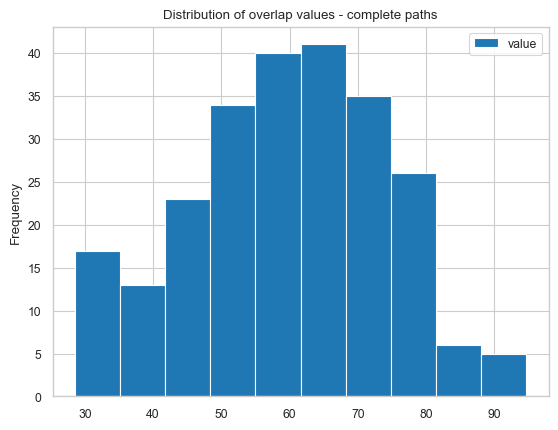

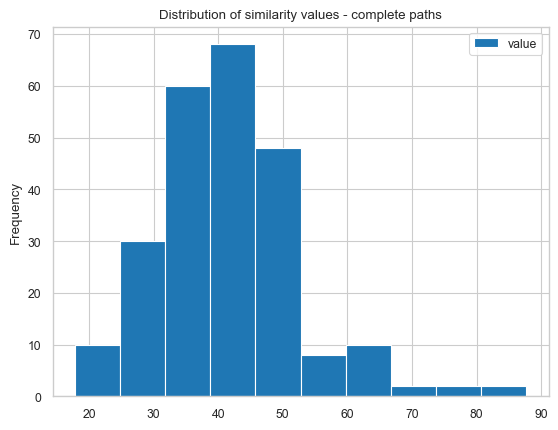

In [50]:
#Let's take a look at the distribution of the overlap and similarity values

prop_bi_shared_complete_paths_df.replace({100:np.nan}).melt().plot(kind='hist')
plt.title('Distribution of overlap values - complete paths')
plt.show()

prop_all_shared_complete_paths_df.replace({100:np.nan}).melt().plot(kind='hist')
plt.title('Distribution of similarity values - complete paths')
plt.show()

In [51]:
#For creating some categorization, it's helpful to know the percentile of the distribution of each value
def find_metab_comparison_percentile_value(metric='overlap',value=50,print_percentile=False):
    if metric == 'overlap':
        all_values = prop_bi_shared_complete_paths_df.replace({100:np.nan}).melt()['value']
    elif metric == 'similarity':
        all_values = prop_all_shared_complete_paths_df.replace({100:np.nan}).melt()['value']
    else:
        raise ValueError('Specify "similarity" or "overlap".')
    above_val = [i for i in all_values if i >= value]
    perc = (1-(len(above_val)/len(all_values)))*100
    if print_percentile==True:
        print(f'{metric}={value} is in the {perc} percentile.')
    return perc

find_metab_comparison_percentile_value(metric='overlap',value=77,print_percentile=True)

overlap=77 is in the 87.5 percentile.


87.5

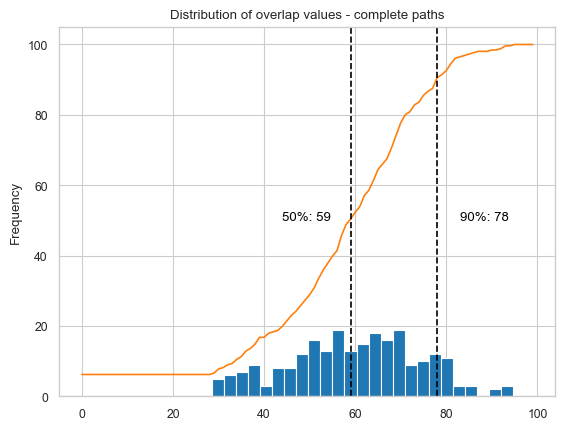

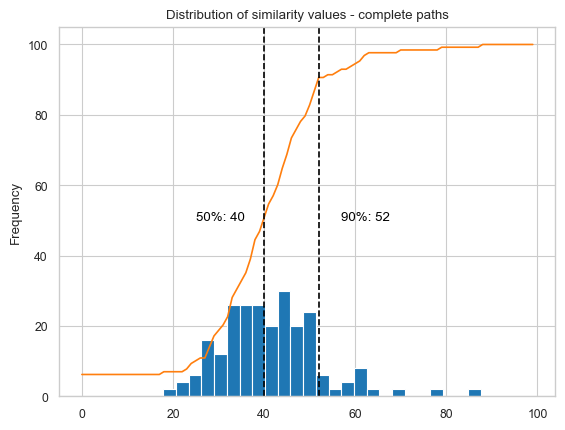

In [52]:
over_percs = []
sim_percs = []

upper_percentile = 90
lower_percentile = 50

for i in range(100):
    over_perc = find_metab_comparison_percentile_value(metric='overlap',value=i)
    over_percs.append(over_perc)
    sim_perc = find_metab_comparison_percentile_value(metric='similarity',value=i)
    sim_percs.append(sim_perc)

red_high,red_low,sim_high,sim_low = np.nan,np.nan,np.nan,np.nan

for i in range(100):
    if over_percs[i] > upper_percentile:
        over_high = i
        break

for i in range(100):
    if over_percs[i] > lower_percentile:
        over_low = i
        break

for i in range(100):
    if sim_percs[i] > upper_percentile:
        sim_high = i
        break

for i in range(100):
    if sim_percs[i] > lower_percentile:
        sim_low = i
        break

prop_bi_shared_complete_paths_df.replace({100:np.nan}).melt().plot(kind='hist',bins=25,legend=False)
pd.Series(over_percs).plot()
plt.axvline(over_high,color='black',linestyle='--')
plt.text(over_high+5,50,f'{upper_percentile}%: {over_high}',color='black')
plt.axvline(over_low,color='black',linestyle='--')
plt.text(over_low-15,50,f'{lower_percentile}%: {over_low}',color='black')
plt.title('Distribution of overlap values - complete paths')
plt.show()

prop_all_shared_complete_paths_df.replace({100:np.nan}).melt().plot(kind='hist',bins=25,legend=False)
pd.Series(sim_percs).plot()
plt.axvline(sim_high,color='black',linestyle='--')
plt.text(sim_high+5,50,f'{upper_percentile}%: {sim_high}',color='black')
plt.axvline(sim_low,color='black',linestyle='--')
plt.text(sim_low-15,50,f'{lower_percentile}%: {sim_low}',color='black')
plt.title('Distribution of similarity values - complete paths')
plt.show()

In [53]:
print("Upper decile overlap:")
prop_bi_shared_complete_paths_df.reset_index().melt(id_vars='index')[prop_bi_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']>=78].loc[prop_bi_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']!=100]

Upper decile overlap:


,index,variable,value
1,Allo 2,Neor 1,94.666667
16,Neor 1,Allo 2,92.207792
35,Robe 5,Lysi 3,83.050847
37,Meso 8,Lysi 3,81.355932
53,Meso 8,Robe 5,86.111111
79,Micr 37,Paen 7,81.081081
83,Robe 5,Meso 8,89.855072
96,Neor 1,Noca 9,78.571429
97,Allo 2,Noca 9,80.952381
113,Allo 2,Lacu 10,79.591837


In [54]:
print("Lower half overlap:")
prop_bi_shared_complete_paths_df.reset_index().melt(id_vars='index')[prop_bi_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']<=59].loc[prop_bi_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']!=100]

Lower half overlap:


,index,variable,value
2,Lysi 3,Neor 1,53.333333
4,Paen 7,Neor 1,33.333333
6,Noca 9,Neor 1,44.000000
7,Lacu 10,Neor 1,50.666667
8,Arth 11,Neor 1,44.000000
...,...,...,...
246,Noca 9,Micr 37,53.703704
247,Lacu 10,Micr 37,57.407407
249,Arth 12,Micr 37,51.851852
251,Baci 14,Micr 37,55.555556


In [55]:
print("Upper decile similarity:")
prop_all_shared_complete_paths_df.reset_index().melt(id_vars='index')[prop_all_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']>=52].loc[prop_all_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']!=100]

Upper decile similarity:


,index,variable,value
1,Allo 2,Neor 1,87.654321
16,Neor 1,Allo 2,87.654321
35,Robe 5,Lysi 3,59.756098
37,Meso 8,Lysi 3,60.000000
50,Lysi 3,Robe 5,59.756098
53,Meso 8,Robe 5,78.481013
59,Baci 14,Robe 5,58.750000
62,Fict 21,Robe 5,69.736842
82,Lysi 3,Meso 8,60.000000
83,Robe 5,Meso 8,78.481013


In [56]:
print("Lower half similarity:")
prop_all_shared_complete_paths_df.reset_index().melt(id_vars='index')[prop_all_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']<=40].loc[prop_all_shared_complete_paths_df.reset_index().melt(id_vars='index')['value']!=100]

Lower half similarity:


,index,variable,value
4,Paen 7,Neor 1,28.735632
6,Noca 9,Neor 1,39.285714
8,Arth 11,Neor 1,36.666667
9,Arth 12,Neor 1,32.530120
11,Baci 14,Neor 1,36.842105
...,...,...,...
237,Flav 20,Fict 21,27.536232
242,Lysi 3,Micr 37,39.506173
250,Para 13,Micr 37,39.024390
251,Baci 14,Micr 37,37.974684


In [57]:
print(f'Complete pathways overlap: median = {prop_bi_shared_complete_paths_df.replace({100:np.nan}).melt()['value'].median():.2f}')
print(f'Complete pathways similarity: median = {prop_all_shared_complete_paths_df.replace({100:np.nan}).melt()['value'].median():.2f}')
print(f'All pathways (complete and partial) overlap: median = {prop_bi_shared_paths_df.replace({100:np.nan}).melt()['value'].median():.2f}')
print(f'All pathways (complete and partial) similarity: median = {prop_all_shared_paths_df.replace({100:np.nan}).melt()['value'].median():.2f}')

Complete pathways overlap: median = 60.42
Complete pathways similarity: median = 40.57
All pathways (complete and partial) overlap: median = 85.25
All pathways (complete and partial) similarity: median = 71.76


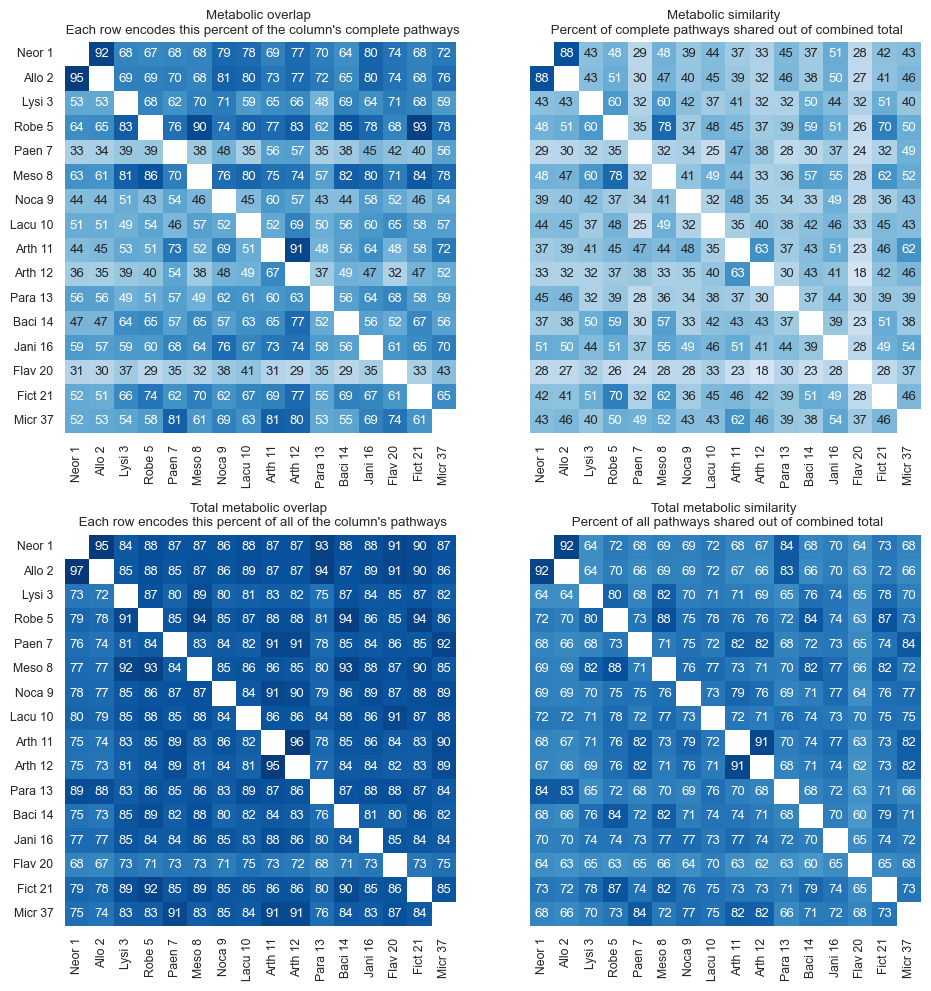

In [58]:
#Illustrate proportion of complete pathways shared between MAGs (niche overlap); for figure
#The plot on the left shows the proportion of the pathways in the column MAG that are found in the row MAG: i.e., 92% of the complete pathways in Allo 2 are found in Neor 1; 80% of the complete pathways found in Jani 16 are found in Neor 1
#The plot on the right shows the proportion of complete pathways that are found in both MAGs relative to the total number of complete pathways they each contain. The higher %, more similar. The lower %, less similar.

sns.set_style('white')
fig,ax = plt.subplots(ncols=2,nrows=2,figsize=(10,10),sharey=True)
sns.heatmap(prop_bi_shared_complete_paths_df.replace({100:np.nan}),square=True,annot=True,vmax=100,vmin=0,cmap='Blues',cbar=False,ax=ax[0,0])
ax[0,0].set_title("Metabolic overlap \n Each row encodes this percent of the column's complete pathways")
sns.heatmap(prop_all_shared_complete_paths_df.replace({100:np.nan}),square=True,annot=True,vmax=100,vmin=0,cmap='Blues',cbar=False,ax=ax[0,1])
ax[0,1].set_title('Metabolic similarity \n Percent of complete pathways shared out of combined total')
sns.heatmap(prop_bi_shared_paths_df.replace({100:np.nan}),square=True,annot=True,vmax=100,vmin=0,cmap='Blues',cbar=False,ax=ax[1,0])
ax[1,0].set_title("Total metabolic overlap \n Each row encodes this percent of all of the column's pathways")
sns.heatmap(prop_all_shared_paths_df.replace({100:np.nan}),square=True,annot=True,vmax=100,vmin=0,cmap='Blues',cbar=False,ax=ax[1,1])
ax[1,1].set_title('Total metabolic similarity \n Percent of all pathways shared out of combined total')
plt.tight_layout()
#plt.savefig('../figs/metab_similarity_matrices_B.pdf',dpi=300,bbox_inches='tight')
plt.show()

In [59]:
#Average overlap each MAG has with others
prop_bi_shared_paths_df.replace({100:np.nan}).mean(axis=1)

Neor 1     88.490415
Allo 2     88.574213
Lysi 3     81.853740
Robe 5     86.774691
Paen 7     83.781484
Meso 8     85.958613
Noca 9     85.605615
Lacu 10    85.620279
Arth 11    83.920569
Arth 12    82.855212
Para 13    86.368826
Baci 14    81.757915
Jani 16    83.487508
Flav 20    71.718007
Fict 21    85.379376
Micr 37    83.556921
dtype: float64

In [60]:
#Which pathways are unique to any given bin; does this distinguish any of the MAGs?
unique_path_df = df_bin_metab_io[df_bin_metab_io.sum(axis=1) == 1]

#List out the unique pathways for each bin that has any since the matrix is hard to interpret
for b in [bin_label_rename_dict[i] for i in good_bin_list]:
    unique_paths = unique_path_df[b][unique_path_df[b] == 1].index.to_list()
    if len(unique_paths) > 0: #only print if the MAG has any unique pathways
        print(b)
        print(unique_paths,'\n')

Neor 1
['Purine degradation, xanthine => urea', 'Trehalose biosynthesis, D-glucose 1P => trehalose'] 

Allo 2
['Betaine degradation, bacteria, betaine => pyruvate'] 

Lysi 3
['Vancomycin resistance, D-Ala-D-Ser type', 'Lysine biosynthesis, DAP dehydrogenase pathway, aspartate => lysine'] 

Meso 8
['Multidrug resistance, efflux pump NorB', 'Cysteine biosynthesis, methionine => cysteine'] 

Para 13
['Tyrosine degradation, tyrosine => homogentisate', 'Ubiquinone biosynthesis, prokaryotes, chorismate (+ polyprenyl-PP) => ubiquinol', 'Multidrug resistance, efflux pump MexJK-OprM', 'Homoprotocatechuate degradation, homoprotocatechuate => 2-oxohept-3-enedioate', 'Phenylalanine biosynthesis, chorismate => phenylpyruvate => phenylalanine', 'Tyrosine biosynthesis, chorismate => HPP => tyrosine', 'Reductive pentose phosphate cycle (Calvin cycle)'] 

Baci 14
['Kanosamine biosynthesis, glucose 6-phosphate => kanosamine'] 

Jani 16
['Ectoine biosynthesis, aspartate => ectoine', 'Catechol meta-cleava

In [61]:
#We can look at which components of pathways each MAG does actually encode by the KOs
df_bin_metab_estimates.iloc[111][0:17]

module                                                                          M00035
bin_name                                                                        Neor 1
module_name                                                     Methionine degradation
module_class                                                           Pathway modules
module_category                                                  Amino acid metabolism
module_subcategory                                  Cysteine and methionine metabolism
module_definition                    K00789 (K00552,K00558,K17398,K17399) K01251 (K...
stepwise_module_completeness                                                       0.5
stepwise_module_is_complete                                                      False
pathwise_module_completeness                                                       0.5
pathwise_module_is_complete                                                      False
proportion_unique_enzymes_present          

In [62]:
#KOs required to complete the pathway
df_bin_metab_estimates['module_definition'].iloc[111]

'K00789 (K00552,K00558,K17398,K17399) K01251 (K01697,K10150)'

In [63]:
#KOs actually encoded by Neor 1 for this path
df_bin_metab_estimates['enzyme_hits_in_module'].iloc[111]

'K00789,K01251'

In [64]:
#A dictionary of which paths are complete for each MAG; I'm pretty sure this is redundant but it works for this specific use case
complete_paths_dict = {}

for b in [bin_label_rename_dict[i] for i in good_bin_list]:
    complete_paths = list(df_bin_metab[b][df_bin_metab[b]==1].index)
    complete_paths_dict[b] = complete_paths

complete_paths_dict['Neor 1']

['Pyruvate oxidation, pyruvate => acetyl-CoA',
 'NADH:quinone oxidoreductase, prokaryotes',
 'Purine degradation, xanthine => urea',
 'Assimilatory nitrate reduction, nitrate => ammonia',
 'Nitrate assimilation',
 'Betaine biosynthesis, choline => betaine',
 'Succinate dehydrogenase, prokaryotes',
 'Ectoine degradation, ectoine => aspartate',
 'Cytochrome bd ubiquinol oxidase',
 'Thiosulfate oxidation by SOX complex, thiosulfate => sulfate',
 'Cytochrome c oxidase, cbb3-type',
 'Denitrification, nitrate => nitrogen',
 'Glutathione biosynthesis, glutamate => glutathione',
 'Cytochrome o ubiquinol oxidase',
 'Ornithine biosynthesis, glutamate => ornithine',
 'Isoleucine biosynthesis, threonine => 2-oxobutanoate => isoleucine',
 'Valine/isoleucine biosynthesis, pyruvate => valine / 2-oxobutanoate => isoleucine',
 'Molybdenum cofactor biosynthesis, GTP => molybdenum cofactor',
 'Proline biosynthesis, glutamate => proline',
 'Tryptophan biosynthesis, chorismate => tryptophan',
 'Cysteine bi

In [65]:
#Which paths are completely encoded in Neor 1 but not Allo 2?
[i for i in complete_paths_dict['Neor 1'] if i not in complete_paths_dict['Allo 2']]

['Purine degradation, xanthine => urea',
 'Cytochrome o ubiquinol oxidase',
 'Trehalose biosynthesis, D-glucose 1P => trehalose',
 'Thiamine salvage pathway, HMP/HET => TMP']

In [66]:
#Which paths are completely encoded in Allo 2 but not Neor 1?
[i for i in complete_paths_dict['Allo 2'] if i not in complete_paths_dict['Neor 1']]

['Nitrogen fixation, nitrogen => ammonia',
 'D-Glucuronate degradation, D-glucuronate => pyruvate + D-glyceraldehyde 3P',
 'dTDP-L-rhamnose biosynthesis',
 'Betaine degradation, bacteria, betaine => pyruvate',
 'Biotin biosynthesis, pimeloyl-ACP/CoA => biotin',
 'Cobalamin biosynthesis, anaerobic, uroporphyrinogen III => sirohydrochlorin => cobyrinate a,c-diamide']

In [67]:
#Let's see how many metabolisms are shared by Bins 1 and 2 to make a real claim about how similar their metabolisms are
#We found this with the similarity value above, just now with slightly more context of what is different
bin_1_paths = complete_paths_dict['Neor 1'] #store pathway modules for Neor 1 here
bin_2_paths = complete_paths_dict['Allo 2'] #store pathway modules for Bin_2 here

shared_paths_1_2 = list(set(complete_paths_dict['Neor 1'])&set(complete_paths_dict['Allo 2']))
not_shared_paths_1 = [path for path in bin_1_paths if path not in bin_2_paths]
not_shared_paths_2 = [path for path in bin_2_paths if path not in bin_1_paths]

print(f'N complete paths Neo: \t \t{len(bin_1_paths)}')
print(f'N complete paths Allo: \t \t{len(bin_2_paths)}')
print(f'N paths shared: \t \t{len(shared_paths_1_2)}')
print(f'N paths exlcusive to Neo: \t{len(not_shared_paths_1)}')
print(f'N paths exlcusive to Allo: \t{len(not_shared_paths_2)}')

N complete paths Neo: 	 	75
N complete paths Allo: 	 	77
N paths shared: 	 	71
N paths exlcusive to Neo: 	4
N paths exlcusive to Allo: 	6


In [68]:
#Pathways that are shared by Neor 1 and Allo 2
shared_paths_1_2

['Serine biosynthesis, glycerate-3P => serine',
 'Leucine biosynthesis, 2-oxoisovalerate => 2-oxoisocaproate',
 'Threonine biosynthesis, aspartate => homoserine => threonine',
 'Polyamine biosynthesis, arginine => ornithine => putrescine',
 'Thiosulfate oxidation by SOX complex, thiosulfate => sulfate',
 'Ornithine biosynthesis, glutamate => ornithine',
 'Cytochrome c oxidase, prokaryotes',
 'Tryptophan biosynthesis, chorismate => tryptophan',
 'Pentose phosphate pathway (Pentose phosphate cycle)',
 'Arginine biosynthesis, ornithine => arginine',
 'beta-Oxidation',
 'Proline degradation, proline => glutamate',
 'C1-unit interconversion, prokaryotes',
 'Nucleotide sugar biosynthesis, glucose => UDP-glucose',
 'Glycolysis (Embden-Meyerhof pathway), glucose => pyruvate',
 'Phosphate acetyltransferase-acetate kinase pathway, acetyl-CoA => acetate',
 'Nitrate assimilation',
 'Assimilatory nitrate reduction, nitrate => ammonia',
 'Cytochrome bd ubiquinol oxidase',
 'Denitrification, nitrate 

In [69]:
#What are the top complete paths encoded by other MAGs but not by Neor 1 nor Allo 2
top_paths_not_in_neo_allo = [i for i in df_bin_metab_io.sum(axis=1).sort_values(ascending=False)[0:100].index if i not in shared_paths_1_2]
df_bin_metab_io.sum(axis=1)[df_bin_metab_io.sum(axis=1).index.isin(top_paths_not_in_neo_allo)].sort_values(ascending=False)[0:75]

module_name
Deoxyribonucleotide biosynthesis, ADP/GDP/CDP/UDP => dATP/dGTP/dCTP/dUTP                                 12.0
Riboflavin biosynthesis, plants and bacteria, GTP => riboflavin/FMN/FAD                                  12.0
Pyridoxal-P biosynthesis, R5P + glyceraldehyde-3P + glutamine => pyridoxal-P                             11.0
Heme biosynthesis, plants and bacteria, glutamate => heme                                                11.0
dTDP-L-rhamnose biosynthesis                                                                              9.0
Heme biosynthesis, bacteria, glutamyl-tRNA => coproporphyrin III => heme                                  9.0
Pantothenate biosynthesis, valine/L-aspartate => pantothenate                                             8.0
Methionine biosynthesis, aspartate => homoserine => methionine                                            7.0
Biotin biosynthesis, pimeloyl-ACP/CoA => biotin                                                           6.

In [70]:
#Let's go back to the N metabolism specifically and see how it varies between the MAGs; specifically DNRA here
df_N_metabs[df_N_metabs['module_name'].str.contains('denitrification',case=False)|df_N_metabs['module_name'].str.contains('dissimilatory nitrate reduction',case=False)]

,module,bin_name,module_name,module_class,module_category,module_subcategory,module_definition,stepwise_module_completeness,stepwise_module_is_complete,pathwise_module_completeness,...,SGW_T3_H11_avg_coverage,SGW_T3_H12_avg_coverage,SGW_T3_H2_avg_coverage,SGW_T3_H3_avg_coverage,SGW_T3_H4_avg_coverage,SGW_T3_H5_avg_coverage,SGW_T3_H6_avg_coverage,SGW_T3_H7_avg_coverage,SGW_T3_H8_avg_coverage,SGW_T3_H9_avg_coverage
57,M00530,Neor 1,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.50,False,0.500000,...,0.089222,17.250085,1.997804,12.778170,20.006942,2.658909,0.568486,0.000000,7.961965,14.236729
58,M00529,Neor 1,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",1.00,True,1.000000,...,0.025492,20.958312,0.776354,13.944578,20.496584,3.051092,1.500777,1.261208,6.005632,11.154672
287,M00530,Allo 2,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.50,False,0.500000,...,0.002660,3.185611,0.000000,0.000000,0.000000,0.712683,0.754634,0.999025,0.963763,0.000000
288,M00529,Allo 2,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",1.00,True,1.000000,...,0.000998,3.465558,0.249814,0.141081,0.000000,0.407137,0.627629,0.374634,1.735370,0.952270
1237,M00530,Paen 7,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.50,False,0.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1448,M00530,Meso 8,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.50,False,0.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1449,M00529,Meso 8,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",0.25,False,0.375000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1653,M00530,Noca 9,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.50,False,0.833333,...,0.000000,2.557197,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1654,M00529,Noca 9,"Denitrification, nitrate => nitrogen",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00368,K...",0.25,False,0.541667,...,0.000000,2.869718,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1872,M00530,Lacu 10,"Dissimilatory nitrate reduction, nitrate => am...",Pathway modules,Energy metabolism,Nitrogen metabolism,"(K00370+K00371+K00374,K02567+K02568) (K00362+K...",0.50,False,0.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [71]:
#We're getting close, but still a little ways from what we really want...
#We can focus in on just DNR and DNRA, but we need to break it down by each step. Especially because DNRA and DNR share the first step. 
KOs_for_DNR = df_N_metabs_melt_info[df_N_metabs_melt_info['module_name'].str.contains('Denitrification')]['module_definition'].iloc[0]
print('Denitrification KOs:','\t',KOs_for_DNR)
KOs_for_DNRA = df_N_metabs_melt_info[df_N_metabs_melt_info['module_name'].str.contains('Dissimilatory')]['module_definition'].iloc[0]
print('DNRA KOs:','\t\t',KOs_for_DNRA)

Denitrification KOs: 	 (K00370+K00371+K00374,K02567+K02568) (K00368,K15864) (K04561+K02305) K00376
DNRA KOs: 		 (K00370+K00371+K00374,K02567+K02568) (K00362+K00363,K03385+K15876)


In [72]:
#Dictionary to connect KO assignments with gene names
denit_gene_KO_dict = {
    'K00370':'narG', #no3 red
    'K00371':'narH',
    'K00374':'narI',
    'K02567':'napA', #no3 red
    'K02568':'napB',
    'K00368':'nirK', #no2 red to NO
    'K15864':'nirS', #no2 red to NO
    'K04561':'norB', #NO red to N2O
    'K02305':'norC',
    'K00376':'nosZ', #N2O red to N2
    'K00362':'nirB', #DNRA; no2 to nh4
    'K00363':'nirD', 
    'K03385':'nrfA', #DNRA; no2 to nh4
    'K15876':'nrfH',
    'K02586':'nifD', #nitrogen fixation
    'K02591':'nifK',
    'K02588':'nirH',
    'K22896':'vnfD', #nitrogen fixation
    'K22897':'vnfK',
    'K22898':'vnfG',
    'K22899':'vnfH',
    'K00531':'anfG', #nitrogen fixation
    'K10535':'hao', #nitrification
    'K10944':'amoA', #nitrification
    'K10945':'amoB',
    'K10946':'amoC',
    'K20932':'hzs', #anammox, all three are hydrazine synthase subunits but the symbols are listed same as the KOs
    'K20933':'hzs',
    'K20934':'hzs',
    'K20935':'hdh' #anammox
}

In [73]:
#List out which genes are in which pathway; probably won't actually use these lists but I like having em.
dissim_no3_red_gene_list = ['narG','narH','narI','napA','napB','nirK','nirS', 'norB', 'norC','nosZ']
dnra_gene_list = ['nirB','nirD','nrfA','nrfH'] #also requires narGHI but not listing for redundancy
n_fix_gene_list = ['nifD','nifK','nirH','vnfD','vnfK','vnfG','vnfH','anfG']
nitrification_gene_list = ['hao','amoA','amoB','amoC']
anammox_gene_list = ['hzs','hdh']

In [74]:
#Figure out which N-metab genes are in each bin
good_bin_N_KO_dict = {}

for b in [bin_label_rename_dict[i] for i in good_bin_list]:
    df_b_gene_calls = bin_gene_calls_dict[b]
    b_KO_list = df_b_gene_calls['KOfam (ACCESSION)'].to_list()
    b_N_gene_list = []
    for ko in denit_gene_KO_dict.keys():
        if ko in b_KO_list:
            b_N_gene_list.append(denit_gene_KO_dict[ko])
    good_bin_N_KO_dict[b] = b_N_gene_list

for k,v in good_bin_N_KO_dict.items():
    print(k,v)

Neor 1 ['napA', 'napB', 'nirK', 'norB', 'norC', 'nosZ']
Allo 2 ['narG', 'narH', 'narI', 'nirK', 'norB', 'norC', 'nosZ', 'nifD', 'nifK', 'nirH']
Lysi 3 []
Robe 5 []
Paen 7 ['nirB', 'nirD']
Meso 8 ['norB', 'nosZ', 'nrfA', 'nrfH']
Noca 9 ['narG', 'narI', 'nirK', 'norB', 'nirB', 'nirD']
Lacu 10 ['nirK', 'nosZ', 'nrfA', 'nrfH', 'nifD', 'nirH']
Arth 11 ['nirB', 'nirD']
Arth 12 ['narI', 'nirB', 'nirD']
Para 13 ['narG', 'narH', 'narI', 'nirB', 'nirD']
Baci 14 ['narG', 'narH', 'narI', 'norB']
Jani 16 ['narG', 'narH', 'narI', 'nirK', 'nirB', 'nirD']
Flav 20 ['norB', 'norC', 'nosZ']
Fict 21 []
Micr 37 ['nirB', 'nirD']


In [75]:
#Create a binary df indicating whether each MAG encodes each gene in the denit_gene_KO_dict

N_gene_bin_binary_dict = {}

for b in good_bin_N_KO_dict.keys():
    dnr_gene_binary = []
    for g in denit_gene_KO_dict.values(): #check each gene by its KO 
        if g in good_bin_N_KO_dict[b]: 
            dnr_gene_binary.append(1) #1 if this MAG encodes that KO
        elif g not in good_bin_N_KO_dict.values():
            dnr_gene_binary.append(0) #0 if it doesn't
    N_gene_bin_binary_dict[b] = dnr_gene_binary

df_N_gene_binary = pd.DataFrame(N_gene_bin_binary_dict,index=denit_gene_KO_dict.values())

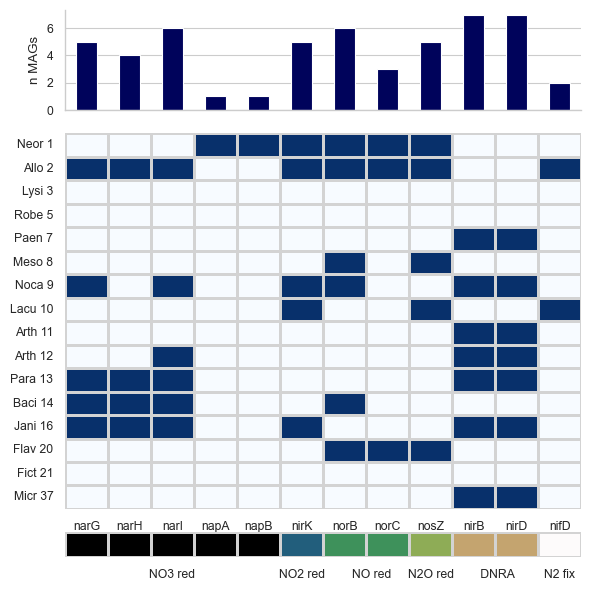

In [76]:
#create a figure showing which of these genes are encoded by which MAG and how many MAGs encode each gene

dnr_genes = ['narG', 'narH', 'narI', 'napA', 'napB', 'nirK','nirB','nirD', 'norB', 'norC', 'nosZ','nifD'] #order of genes to check

sns.set_style('whitegrid')
fig,ax=plt.subplots(nrows=3,figsize=(6,6),sharex=False,height_ratios=(.2,.75,.05))

#Create a bar plot showing how many MAGs encode each gene
df_N_gene_binary[df_N_gene_binary.index.isin(dnr_genes)].T.sum().plot(kind='bar',ax=ax[0],color='xkcd:dark blue')
ax[0].set_ylabel('n MAGs')
ax[0].set_xticks([])
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

#Create the binary heatmap showing which genes are encoded by each MAG; note: these boxes are recolored in illustrator to match the key in the bottom row
sns.heatmap(df_N_gene_binary[df_N_gene_binary.index.isin(dnr_genes)].T.rename(index=bin_label_rename_dict),cmap='Blues',cbar=False,linewidths=.75,linecolor='lightgrey',ax=ax[1])

#Create a dummy heatmap to separate the genes into steps of the pathways
sns.heatmap(pd.DataFrame([1,1,1,1,1,2,3,3,4,5,5,6]).T,
                    cmap='gist_earth',cbar=False,linewidths=.75,linecolor='lightgrey',ax=ax[2])
ax[2].set_xticklabels(['','','NO3 red','','','NO2 red','                NO red','','N2O red','              DNRA','','N2 fix']) #label spacing is weird
ax[2].set_yticks([])

plt.tight_layout(h_pad=0)

#plt.savefig('../figs/MAGs_N_metab.pdf',dpi=300,bbox_inches='tight')

plt.show()

In [77]:
#transporters?
b1_gene_calls = bin_gene_calls_dict['Neor 1']
b1_gene_calls

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
0,19547,contig_953,22,1225,f,none,none,none,none,"Mobilome: prophages, transposons",X,transposase,K07486,none,none,KEGG Orthology (KO)>>>09190 Not Included in Pa...,ko00001,Transposase,COG3547,ATGCGGTCGATCGGAATGGATGTGCATCGAAGTTTTGCGCAGGTCG...
1,19548,contig_953,1434,1686,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,ATGCATTTTCCGAGAAACCGCTGGCGTCTCGATGACCATGGCCGCA...
2,19549,contig_953,1704,2418,r,none,none,none,none,"Mobilome: prophages, transposons",X,none,none,none,none,none,none,Transposase,COG3436,ATGCCACTAGCTCACACTGTGTTTGTTCGCCGGGCTCGACGGAACT...
3,19550,contig_953,2873,3305,r,none,none,none,none,Energy production and conversion,C,none,none,none,none,none,none,Cytochrome c553 (CytC553) (PDB:6Q2U),COG2863,ATGAACAACGGAAAGATCATCATTGTTGCAGTTGCGGTCGCAGCGA...
4,19551,contig_953,3453,3888,r,none,none,none,none,Energy production and conversion,C,none,none,none,none,none,none,"Cytochrome c, mono- and diheme variants (CccA)...",COG2010,GTGAGGCAGTTCTGGATCGCAGCCGCTGCAATTCTTCCGTTGGCTG...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5900,154926,contig_11,13,1532,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TCGTAAGGGCATTTGGTGGATGCCTTGGCATGCACAGGCGAAGAAG...
5901,155017,contig_18,4839,6326,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TTTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATG...
5902,155019,contig_20,203394,204863,f,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATGC...
5903,155020,contig_20,2591,4060,r,none,none,none,none,none,none,none,none,none,none,none,none,none,none,TTTGATCCTGGCTCAGAACGAACGCTGGCGGCAGGCTTAACACATG...


In [78]:
b1_gene_calls[b1_gene_calls['KOfam'].str.contains('transport',case=False)].loc[b1_gene_calls['KOfam'].str.contains('nitrate',case=False)]#['KOfam'].unique()

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
2220,93351,contig_11,164686,165952,r,Signature modules; Module set; Metabolic capacity,M00615,Nitrate assimilation,M00615,Inorganic ion transport and metabolism,P,"MFS transporter, NNP family, nitrate/nitrite t...",K02575,none,none,KEGG Orthology (KO)>>>09100 Metabolism>>>09102...,ko00001!!!ko02000,Nitrate/nitrite transporter NarK (NarK) (PDB:4...,COG2223,ATGTCTGTACTTGAGAAAACGCAGCCCATGTCCGCCGGCGAACCAG...


In [79]:
b1_gene_calls[b1_gene_calls['KOfam'].str.contains('transport',case=False)].loc[b1_gene_calls['KOfam'].str.contains('amino acid',case=False)]

,gene_callers_id,contig,start,stop,direction,KEGG_Class,KEGG_Class (ACCESSION),KEGG_Module,KEGG_Module (ACCESSION),COG20_CATEGORY,COG20_CATEGORY (ACCESSION),KOfam,KOfam (ACCESSION),COG20_PATHWAY,COG20_PATHWAY (ACCESSION),KEGG_BRITE,KEGG_BRITE (ACCESSION),COG20_FUNCTION,COG20_FUNCTION (ACCESSION),dna_sequence
384,32690,contig_8,146365,147151,f,none,none,none,none,Amino acid transport and metabolism,E,polar amino acid transport system ATP-binding ...,K02028,none,none,Enzymes>>>7. Translocases>>>7.4 Catalysing th...,ko01000!!!ko02000,"ABC-type polar amino acid transport system, AT...",COG1126,ATGCCATCACCCATCATCCGTATCGACAACATCGTGAAGAGGTTCG...
385,32691,contig_8,147211,148057,f,none,none,none,none,Amino acid transport and metabolism!!!Signal t...,E!!!T,polar amino acid transport system substrate-bi...,K02030,none,none,"Transporters>>>ABC transporters, prokaryotic t...",ko02000,ABC-type amino acid transport/signal transduct...,COG0834,ATGAAGACAAGAATTCTCGCCACTGCTGCCGGCATTGCGGCCTTTA...
386,32692,contig_8,148184,148844,f,none,none,none,none,Amino acid transport and metabolism,E,polar amino acid transport system permease pro...,K02029,none,none,"Transporters>>>ABC transporters, prokaryotic t...",ko02000,"ABC-type amino acid transport system, permease...",COG0765,ATGATTGACTGGTCCGGCTATCTGTCGCTGATTCTGGAAGGCGCGC...
387,32693,contig_8,148846,149506,f,none,none,none,none,Amino acid transport and metabolism,E,polar amino acid transport system permease pro...,K02029,none,none,"Transporters>>>ABC transporters, prokaryotic t...",ko02000,"ABC-type amino acid transport system, permease...",COG0765,ATGGAATGGGATTGGGATTTCGTCTGGCAGATCATGCCGACCCTTC...
744,33050,contig_8,555695,556913,f,none,none,none,none,Amino acid transport and metabolism,E,branched-chain amino acid transport system sub...,K01999,none,none,KEGG Orthology (KO)>>>09130 Environmental Info...,ko00001!!!ko00001!!!ko02000,ABC-type branched-chain amino acid transport s...,COG0683,ATGCGCAAGACACTTCTGACATCTCTGGCTGTCCTTTTTGCAAGCA...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5828,140955,contig_3,3391990,3393118,f,none,none,none,none,Amino acid transport and metabolism,E,branched-chain amino acid transport system sub...,K01999,none,none,KEGG Orthology (KO)>>>09130 Environmental Info...,ko00001!!!ko00001!!!ko02000,ABC-type branched-chain amino acid transport s...,COG0683,ATGATCAGGAAACTACTTTCTACAGCTGCAATTTTCGTGGCCTGCA...
5829,140956,contig_3,3393211,3394090,f,none,none,none,none,Amino acid transport and metabolism,E,branched-chain amino acid transport system per...,K01997,none,none,KEGG Orthology (KO)>>>09130 Environmental Info...,ko00001!!!ko00001!!!ko02000,Branched-chain amino acid ABC-type transport s...,COG0559,ATGGCCGAGCTTATCCAGATTCTCATCTCCGGCCTTGCCGCCGGTT...
5830,140957,contig_3,3394086,3395061,f,none,none,none,none,Amino acid transport and metabolism,E,branched-chain amino acid transport system per...,K01998,none,none,KEGG Orthology (KO)>>>09130 Environmental Info...,ko00001!!!ko00001!!!ko02000,ABC-type branched-chain amino acid transport s...,COG4177,ATGACCCGCCTTCAACCCGTCCTTTTCGTTCTCGGCATCGCTGCGC...
5831,140958,contig_3,3395057,3395810,f,none,none,none,none,Amino acid transport and metabolism,E,branched-chain amino acid transport system ATP...,K01995,none,none,KEGG Orthology (KO)>>>09130 Environmental Info...,ko00001!!!ko00001!!!ko02000,ABC-type branched-chain amino acid transport s...,COG0411,GTGAACATCAACGCACCCATCCTTTCCGTCCATAACATTTCCAAGC...
